### Run this notebook online

[![Open in Colab](https://img.shields.io/badge/Open_in-Colab-F9AB00?logo=googlecolab&logoColor=F9AB00)](https://colab.research.google.com/github/hosein-fanai/Continual-Learning-with-Diffusion-Vision-Transformers/blob/main/files/notebooks/CIFAR10%20DiT.ipynb)
[![Open in Kaggle](https://kaggle.com/static/images/open-in-kaggle.svg)](https://www.kaggle.com/kernels/welcome?src=https%3A%2F%2Fgithub.com%2Fhosein-fanai%2FContinual-Learning-with-Diffusion-Vision-Transformers%2Fblob%2Fmain%2Ffiles%2Fnotebooks%2FCIFAR10%2520DiT.ipynb)
[![Launch Binder](https://img.shields.io/badge/launch-binder-F5793A?logo=jupyter&logoColor=white)](https://mybinder.org/v2/gh/hosein-fanai/Continual-Learning-with-Diffusion-Vision-Transformers/main?urlpath=lab%2Ftree%2Ffiles%2Fnotebooks%2FCIFAR10%20DiT.ipynb)

- **Google Colab:** open the notebook, select a GPU for training under **Runtime > Change runtime type**, then choose **Run all**.
- **Kaggle:** sign in and import the notebook, enable **Internet**, select a **GPU** accelerator for training, then **Run all**.
- **Binder:** opens a temporary CPU JupyterLab session. Use it to inspect the notebook or run small checks; full training needs more resources.
- **[Studio Lab](https://studiolab.sagemaker.aws/import/github/hosein-fanai/Continual-Learning-with-Diffusion-Vision-Transformers/blob/main/files/notebooks/CIFAR10%20DiT.ipynb) (existing accounts only):** start a runtime, copy the notebook to your project, select a Python **3.11–3.13** kernel, and set `RUNTIME = "studiolab"` in the first code cell before **Run all**. For CPU, also set `CUDA = False`.

The **first code cell** finds or downloads the repository and prepares TensorFlow **2.20** / Keras **3.11.2** before project imports. If setup requests a restart, restart the kernel and run all again. For another hosted Jupyter service, set `RUNTIME = "hosted"` (`CUDA = False` for CPU or compatible provider-managed CUDA). Locally, select the project TensorFlow kernel.

Launch links open the published GitHub `main` version; publish this notebook and its setup files together before using them. For a notebook that has not been published, upload its `.ipynb` file to Colab or Kaggle instead. GPU availability depends on the provider. Save checkpoints and results before a temporary session ends.

See the [hosted runtime guide](https://github.com/hosein-fanai/Continual-Learning-with-Diffusion-Vision-Transformers/blob/main/files/notebooks/thesis/README.md#hosted-runtimes) for setup and import details.


In [1]:
"""Prepare a notebook checkout and runtime before importing scientific packages.

This canonical first-cell source is copied into maintained notebooks and generated
HPO notebooks. Edit REVISION/RUNTIME/CUDA before execution when needed. Existing
checkouts are reused without fetching; only missing setup code is downloaded.
ROOT is the selected absolute pathlib.Path; RUNTIME_PACKAGES maps package names
to installed version strings. Preparation may clone/install under the selected
policy and changes cwd/import paths through files.notebooks.init.prepare_notebook.
"""
from pathlib import Path
from urllib.request import urlopen


CHECKOUT_NAME = "Continual-Learning-with-Diffusion-Vision-Transformers"
REPOSITORY = f"https://github.com/hosein-fanai/{CHECKOUT_NAME}.git"
REVISION = "main"
RUNTIME = "local"  # Use "hosted" for another online service, or "local" to verify only.
CUDA = None  # False: CPU or managed CUDA; True: retain CUDA pip dependencies.

_locations = (Path.cwd(), *Path.cwd().parents, Path.cwd() / CHECKOUT_NAME, 
              Path("/kaggle/working") / CHECKOUT_NAME, Path("/content") / CHECKOUT_NAME)
_initializer = next((path / "files" / "notebooks" / "init.py" for path in _locations
                     if (path / "files" / "notebooks" / "init.py").is_file()), None)
_url = f"https://raw.githubusercontent.com/hosein-fanai/{CHECKOUT_NAME}/{REVISION}/files/notebooks/init.py"
_setup = {"__name__": "notebook_setup", "__file__": str(_initializer or _url)}
with (_initializer.open("rb") if _initializer else urlopen(_url, timeout=30)) as _file:
    exec(compile(_file.read(), _setup["__file__"], "exec"), _setup)
ROOT, RUNTIME_PACKAGES = _setup["prepare_notebook"](
    checkout_name=CHECKOUT_NAME, 
    repository=REPOSITORY, 
    revision=REVISION, 
    runtime=RUNTIME, 
    cuda=CUDA
)

Repository ready: /workspace/continual_learning_with_diffusion_vision_transformers (runtime: local)
Runtime packages ready: Python 3.12.3, TensorFlow 2.20.0, Keras 3.11.2


In [2]:
from common import utils


utils.init()

2026-10-15 23:01:30.289092: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-10-15 23:01:30.343168: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-10-15 23:01:31.517442: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## Experiment settings


In [3]:
stages_num = 25
epochs = 10
val_freq = 5

## CIFAR10 data


In [4]:
from common.dataloader import load_cifar10, get_dataset


x_train, y_train, _, _, x_test, y_test = load_cifar10(
    indices=None, 
    validation_ratio=0.0, 
    verbose=0
)

trainset = get_dataset(x_train, y_train.reshape(-1))
valset = get_dataset(x_test, y_test.reshape(-1), shuffle_buffer=0, drop_remainder=False)

2026-10-15 23:01:38.035799: W tensorflow/core/common_runtime/gpu/gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was 0.
I0000 00:00:1792105298.037050     998 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 79194 MB memory:  -> device: 0, name: NVIDIA A100-SXM4-80GB, pci bus id: 0000:0a:00.0, compute capability: 8.0


## DiT denoiser


In [5]:
from diffusion.models.transformer.diffusion_transformer import DiffusionTransformer
from diffusion.models.wrapper.diffusion_model import DiffusionModel


vit = DiffusionTransformer(
    image_size=32, 
    channels=3, 
    dim=128, 
    depth=6, 
    mha_num_heads=4, 
    patchify_with_cnn=True, 
    use_refiner_cnn=True
)
model = DiffusionModel(network=vit, p_uncond=0.2)

vit.summary()

Model: "diffusion_transformer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ depth_0_patch_embedder          │ (None, 256, 128)       │        75,648 │
│ (PatchEmbedding)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_0_time_embedder           │ (None, 128)            │       128,000 │
│ (ConditionEmbedding)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_0_label_embedder          │ (None, 128)            │         1,408 │
│ (ConditionEmbedding)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_0_time_label_merger (Add) │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_1_encoder_block           │ (None, 256, 128)       │       296,838 │
│ (VisionTransformerBlock)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_2_encoder_block           │ (None, 256, 128)       │       296,838 │
│ (VisionTransformerBlock)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_3_encoder_block           │ (None, 256, 128)       │       296,838 │
│ (VisionTransformerBlock)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_4_encoder_block           │ (None, 256, 128)       │       296,838 │
│ (VisionTransformerBlock)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_5_encoder_block           │ (None, 256, 128)       │       296,838 │
│ (VisionTransformerBlock)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depth_6_encoder_block           │ (None, 256, 128)       │       296,838 │
│ (VisionTransformerBlock)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ unpatchifier (Functional)       │ (None, 32, 32, 3)      │        41,615 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,027,699 (7.74 MB)

 Trainable params: 1,899,663 (7.25 MB)

 Non-trainable params: 128,036 (500.28 KB)

## Optimizer


In [6]:
from tensorflow.keras import optimizers


lr_schedule = optimizers.schedules.CosineDecay(
    initial_learning_rate=0.004845009591308682, # 5e-3
    decay_steps=(stages_num+1) * epochs * len(trainset) 
)

model.compile(
    optimizer=optimizers.Adam(
        lr_schedule, 
        global_clipnorm=1.0
    ), 
    loss="mse"
)

In [7]:
from tensorflow.keras import callbacks

from common.callbacks.lr_logger import LrLogger

from diffusion.callbacks.image_generator import ImageGenerator


callbacks_list = [
    LrLogger(), 
    callbacks.ProgbarLogger(), 
    ImageGenerator(frequency=val_freq)
]

## Training


Progressive stage 1/25: changes={'timesteps': (995, 1000)}, resolution=32, sampling t in [995, 1000) range.
Epoch 1/10


2026-10-15 23:01:53.922070: I external/local_xla/xla/service/service.cc:163] XLA service 0x7c1210002210 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2026-10-15 23:01:53.922096: I external/local_xla/xla/service/service.cc:171]   StreamExecutor device (0): NVIDIA A100-SXM4-80GB, Compute Capability 8.0
2026-10-15 23:01:54.275178: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
2026-10-15 23:01:56.371882: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:473] Loaded cuDNN version 91002
2026-10-15 23:01:57.596783: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
2026-10-15 23:01:57.597070: I ext

  1/390 ━━━━━━━━━━━━━━━━━━━━ 12:27:29 115s/step - noise_loss: 0.9979

I0000 00:00:1792105417.631108    1525 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


390/390 ━━━━━━━━━━━━━━━━━━━━ 131s 39ms/step - noise_loss: 0.0345 - learning_rate: 0.0048
Epoch 2/10
390/390 ━━━━━━━━━━━━━━━━━━━━ 10s 25ms/step - noise_loss: 5.8011e-04 - learning_rate: 0.0048
Epoch 3/10
390/390 ━━━━━━━━━━━━━━━━━━━━ 10s 24ms/step - noise_loss: 4.3356e-04 - learning_rate: 0.0048
Epoch 4/10
390/390 ━━━━━━━━━━━━━━━━━━━━ 10s 25ms/step - noise_loss: 5.2587e-04 - learning_rate: 0.0048
Epoch 5/10
388/390 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - noise_loss: 2.5339e-04

2026-10-15 23:04:43.177095: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot', 4 bytes spill stores, 4 bytes spill loads

2026-10-15 23:04:43.616733: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_6', 276 bytes spill stores, 276 bytes spill loads

2026-10-15 23:04:53.610783: I external/local_xla/xla/service/gpu/autotuning/dot_search_space.cc:208] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.
2026-10-15 23:05:00.819828: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_172', 32 bytes spill

390/390 ━━━━━━━━━━━━━━━━━━━━ 57s 148ms/step - noise_loss: 3.0102e-04 - val_image_loss: 0.9907 - val_loss: 0.2246 - val_noise_loss: 0.2246 - learning_rate: 0.0048
Steps: 50/50


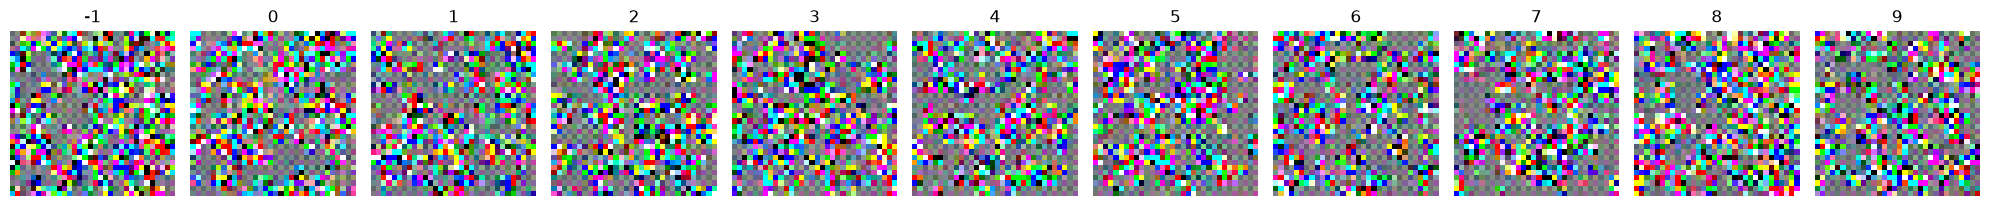

Epoch 6/10
390/390 ━━━━━━━━━━━━━━━━━━━━ 10s 25ms/step - noise_loss: 2.6042e-04 - learning_rate: 0.0048
Epoch 7/10
390/390 ━━━━━━━━━━━━━━━━━━━━ 10s 25ms/step - noise_loss: 2.8628e-04 - learning_rate: 0.0048
Epoch 8/10
390/390 ━━━━━━━━━━━━━━━━━━━━ 10s 25ms/step - noise_loss: 3.0045e-04 - learning_rate: 0.0048
Epoch 9/10
390/390 ━━━━━━━━━━━━━━━━━━━━ 10s 25ms/step - noise_loss: 2.5280e-04 - learning_rate: 0.0048
Epoch 10/10
390/390 ━━━━━━━━━━━━━━━━━━━━ 23s 58ms/step - noise_loss: 0.2826 - val_image_loss: 11.7068 - val_loss: 0.3212 - val_noise_loss: 0.3212 - learning_rate: 0.0048
Steps: 50/50


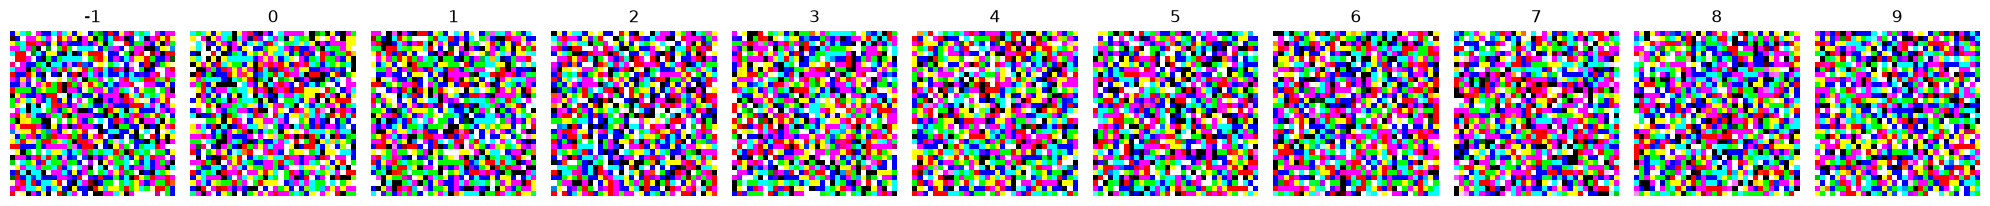

Progressive stage 2/25: changes={'timesteps': (991, 1000)}, resolution=32, sampling t in [991, 1000) range.
Epoch 11/20
390/390 ━━━━━━━━━━━━━━━━━━━━ 29s 25ms/step - noise_loss: 0.0019 - learning_rate: 0.0048
Epoch 12/20
390/390 ━━━━━━━━━━━━━━━━━━━━ 14s 36ms/step - noise_loss: 5.2985e-04 - learning_rate: 0.0048
Epoch 13/20
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 29ms/step - noise_loss: 3.9591e-04 - learning_rate: 0.0048
Epoch 14/20
390/390 ━━━━━━━━━━━━━━━━━━━━ 17s 44ms/step - noise_loss: 3.3006e-04 - learning_rate: 0.0048
Epoch 15/20
390/390 ━━━━━━━━━━━━━━━━━━━━ 29s 74ms/step - noise_loss: 3.1863e-04 - val_image_loss: 8.9189 - val_loss: 1.0412 - val_noise_loss: 1.0412 - learning_rate: 0.0048
Steps: 50/50


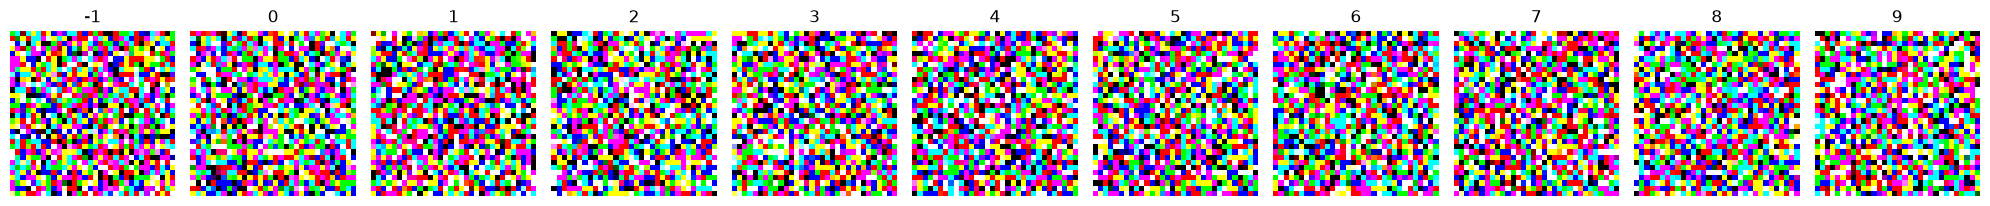

Epoch 16/20
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 48ms/step - noise_loss: 2.9785e-04 - learning_rate: 0.0048
Epoch 17/20
390/390 ━━━━━━━━━━━━━━━━━━━━ 12s 29ms/step - noise_loss: 2.9784e-04 - learning_rate: 0.0048
Epoch 18/20
390/390 ━━━━━━━━━━━━━━━━━━━━ 10s 25ms/step - noise_loss: 3.0068e-04 - learning_rate: 0.0048
Epoch 19/20
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 3.0482e-04 - learning_rate: 0.0048
Epoch 20/20
390/390 ━━━━━━━━━━━━━━━━━━━━ 26s 68ms/step - noise_loss: 2.7652e-04 - val_image_loss: 12.6015 - val_loss: 1.1935 - val_noise_loss: 1.1935 - learning_rate: 0.0048
Steps: 50/50


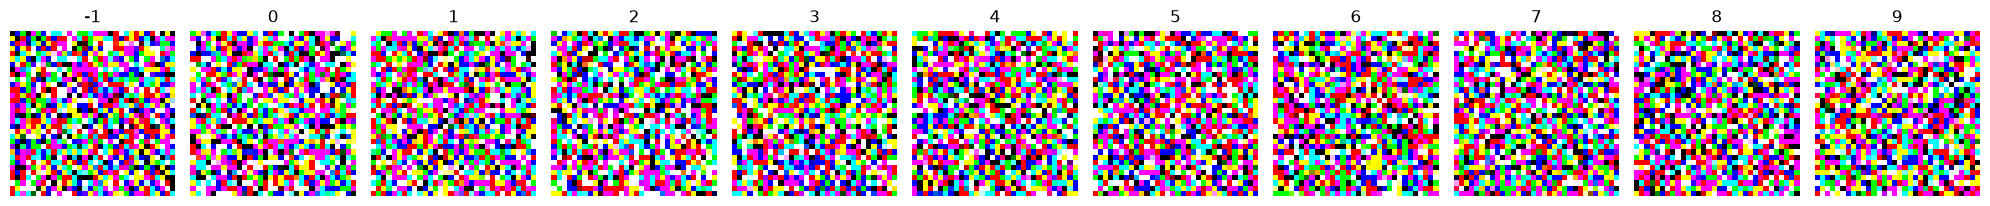

Progressive stage 3/25: changes={'timesteps': (985, 1000)}, resolution=32, sampling t in [985, 1000) range.
Epoch 21/30
390/390 ━━━━━━━━━━━━━━━━━━━━ 32s 27ms/step - noise_loss: 0.0906 - learning_rate: 0.0048
Epoch 22/30
390/390 ━━━━━━━━━━━━━━━━━━━━ 10s 25ms/step - noise_loss: 6.2134e-04 - learning_rate: 0.0048
Epoch 23/30
390/390 ━━━━━━━━━━━━━━━━━━━━ 14s 36ms/step - noise_loss: 4.2070e-04 - learning_rate: 0.0048
Epoch 24/30
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 48ms/step - noise_loss: 3.7325e-04 - learning_rate: 0.0047
Epoch 25/30
390/390 ━━━━━━━━━━━━━━━━━━━━ 33s 84ms/step - noise_loss: 3.4505e-04 - val_image_loss: 29.0294 - val_loss: 8.4809 - val_noise_loss: 8.4809 - learning_rate: 0.0047
390/390 ━━━━━━━━━━━━━━━━━━━━ 13s 32ms/step - noise_loss: 3.3213e-04 - learning_rate: 0.0047
Epoch 27/30
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 29ms/step - noise_loss: 3.1230e-04 - learning_rate: 0.0047
Epoch 28/30
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 3.2312e-04 - learning_rate: 0.0047
Epoch 

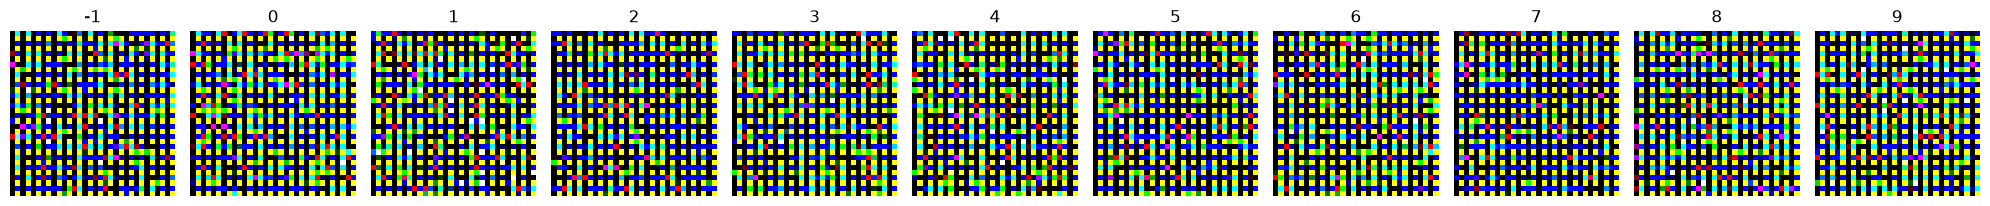

Progressive stage 4/25: changes={'timesteps': (978, 1000)}, resolution=32, sampling t in [978, 1000) range.
Epoch 31/40
390/390 ━━━━━━━━━━━━━━━━━━━━ 33s 35ms/step - noise_loss: 0.0059 - learning_rate: 0.0047
Epoch 32/40
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 29ms/step - noise_loss: 3.6304e-04 - learning_rate: 0.0047
Epoch 33/40
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 3.4063e-04 - learning_rate: 0.0047
Epoch 34/40
390/390 ━━━━━━━━━━━━━━━━━━━━ 10s 25ms/step - noise_loss: 3.4164e-04 - learning_rate: 0.0046
Epoch 35/40
390/390 ━━━━━━━━━━━━━━━━━━━━ 26s 67ms/step - noise_loss: 3.3752e-04 - val_image_loss: 20.2238 - val_loss: 3.5354 - val_noise_loss: 3.5354 - learning_rate: 0.0046
Steps: 50/50


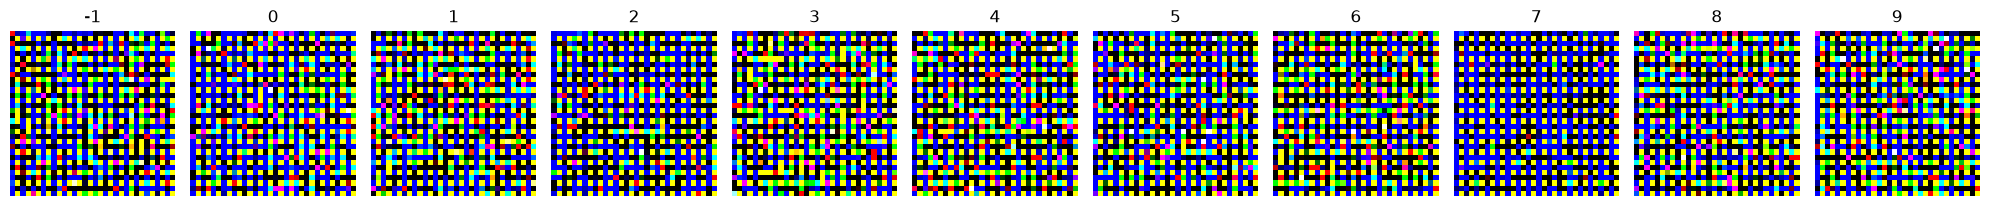

Epoch 36/40
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 48ms/step - noise_loss: 3.5853e-04 - learning_rate: 0.0046
Epoch 37/40
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 48ms/step - noise_loss: 3.8887e-04 - learning_rate: 0.0046
Epoch 38/40
390/390 ━━━━━━━━━━━━━━━━━━━━ 15s 38ms/step - noise_loss: 3.4593e-04 - learning_rate: 0.0046
Epoch 39/40
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 3.7988e-04 - learning_rate: 0.0046
Epoch 40/40
390/390 ━━━━━━━━━━━━━━━━━━━━ 24s 60ms/step - noise_loss: 3.5040e-04 - val_image_loss: 19.0454 - val_loss: 3.2040 - val_noise_loss: 3.2040 - learning_rate: 0.0046
Steps: 50/50


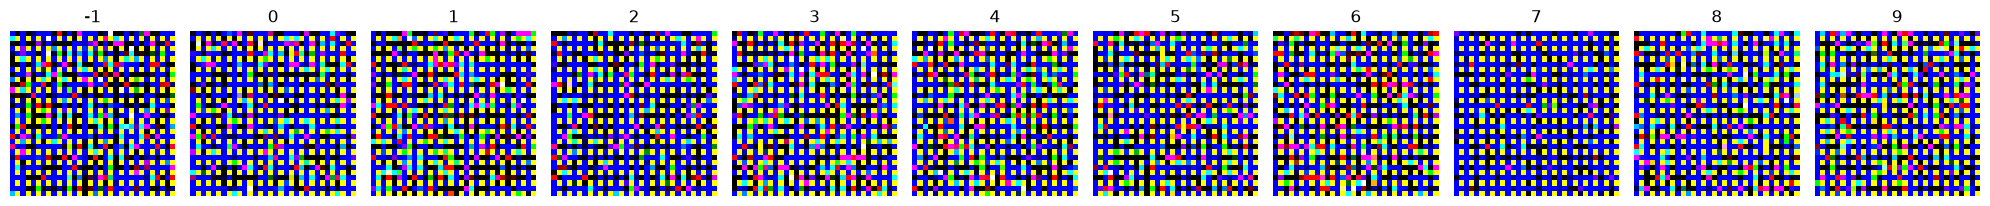

Progressive stage 5/25: changes={'timesteps': (970, 1000)}, resolution=32, sampling t in [970, 1000) range.
Epoch 41/50
390/390 ━━━━━━━━━━━━━━━━━━━━ 38s 49ms/step - noise_loss: 0.0029 - learning_rate: 0.0046
Epoch 42/50
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 48ms/step - noise_loss: 4.3129e-04 - learning_rate: 0.0045
Epoch 43/50
390/390 ━━━━━━━━━━━━━━━━━━━━ 16s 41ms/step - noise_loss: 4.2196e-04 - learning_rate: 0.0045
Epoch 44/50
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 4.1046e-04 - learning_rate: 0.0045
Epoch 45/50
390/390 ━━━━━━━━━━━━━━━━━━━━ 24s 62ms/step - noise_loss: 4.1725e-04 - val_image_loss: 19.7115 - val_loss: 3.7394 - val_noise_loss: 3.7394 - learning_rate: 0.0045
Steps: 50/50


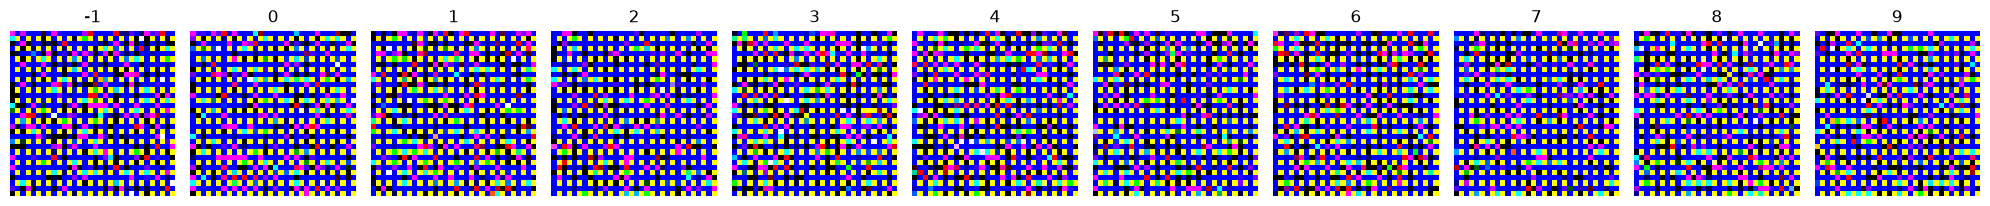

Epoch 46/50
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 49ms/step - noise_loss: 4.3736e-04 - learning_rate: 0.0045
Epoch 47/50
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 49ms/step - noise_loss: 4.1988e-04 - learning_rate: 0.0045
Epoch 48/50
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 48ms/step - noise_loss: 4.2713e-04 - learning_rate: 0.0044
Epoch 49/50
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 49ms/step - noise_loss: 4.3263e-04 - learning_rate: 0.0044
Epoch 50/50
390/390 ━━━━━━━━━━━━━━━━━━━━ 30s 76ms/step - noise_loss: 4.3586e-04 - val_image_loss: 15.5780 - val_loss: 2.9940 - val_noise_loss: 2.9940 - learning_rate: 0.0044
Steps: 50/50


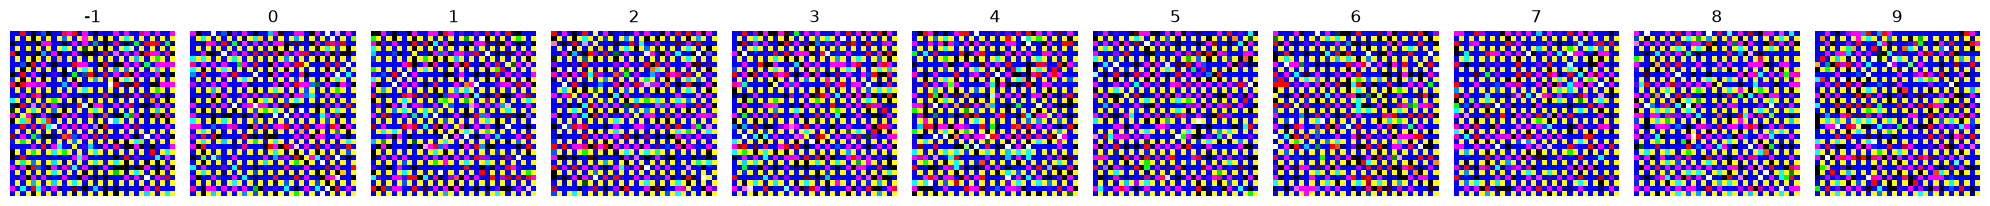

Progressive stage 6/25: changes={'timesteps': (960, 1000)}, resolution=32, sampling t in [960, 1000) range.
Epoch 51/60
390/390 ━━━━━━━━━━━━━━━━━━━━ 37s 47ms/step - noise_loss: 0.0013 - learning_rate: 0.0044
Epoch 52/60
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 48ms/step - noise_loss: 5.3284e-04 - learning_rate: 0.0044
Epoch 53/60
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 47ms/step - noise_loss: 5.2508e-04 - learning_rate: 0.0044
Epoch 54/60
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 48ms/step - noise_loss: 5.2597e-04 - learning_rate: 0.0043
Epoch 55/60
390/390 ━━━━━━━━━━━━━━━━━━━━ 32s 83ms/step - noise_loss: 5.3444e-04 - val_image_loss: 13.6621 - val_loss: 2.8012 - val_noise_loss: 2.8012 - learning_rate: 0.0043
Steps: 50/50


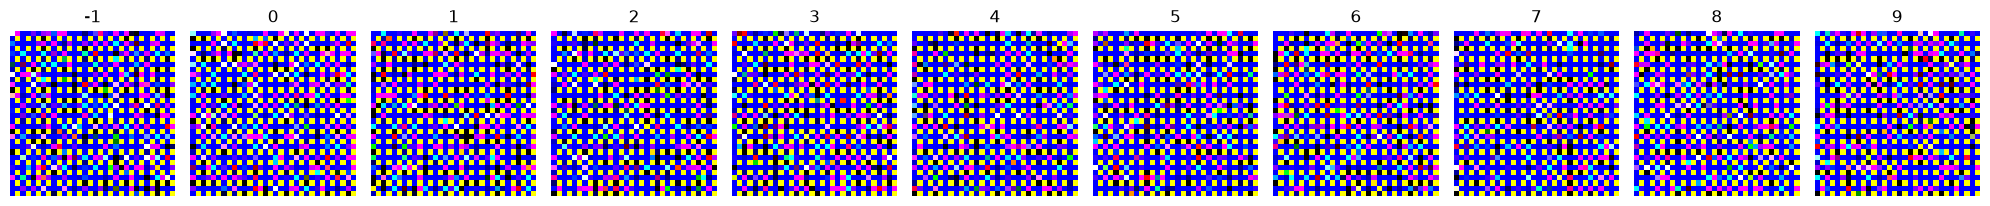

Epoch 56/60
390/390 ━━━━━━━━━━━━━━━━━━━━ 10s 25ms/step - noise_loss: 5.4424e-04 - learning_rate: 0.0043
Epoch 57/60
390/390 ━━━━━━━━━━━━━━━━━━━━ 10s 25ms/step - noise_loss: 5.4596e-04 - learning_rate: 0.0043
Epoch 58/60
390/390 ━━━━━━━━━━━━━━━━━━━━ 29s 26ms/step - noise_loss: 0.0168 - learning_rate: 0.0042
Epoch 62/70
390/390 ━━━━━━━━━━━━━━━━━━━━ 10s 25ms/step - noise_loss: 8.1516e-04 - learning_rate: 0.0042
Epoch 63/70
390/390 ━━━━━━━━━━━━━━━━━━━━ 17s 43ms/step - noise_loss: 7.5210e-04 - learning_rate: 0.0042
Epoch 64/70
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 49ms/step - noise_loss: 7.3823e-04 - learning_rate: 0.0042
Epoch 65/70
390/390 ━━━━━━━━━━━━━━━━━━━━ 33s 85ms/step - noise_loss: 7.2574e-04 - val_image_loss: 18.7027 - val_loss: 3.9908 - val_noise_loss: 3.9908 - learning_rate: 0.0041
Steps: 50/50


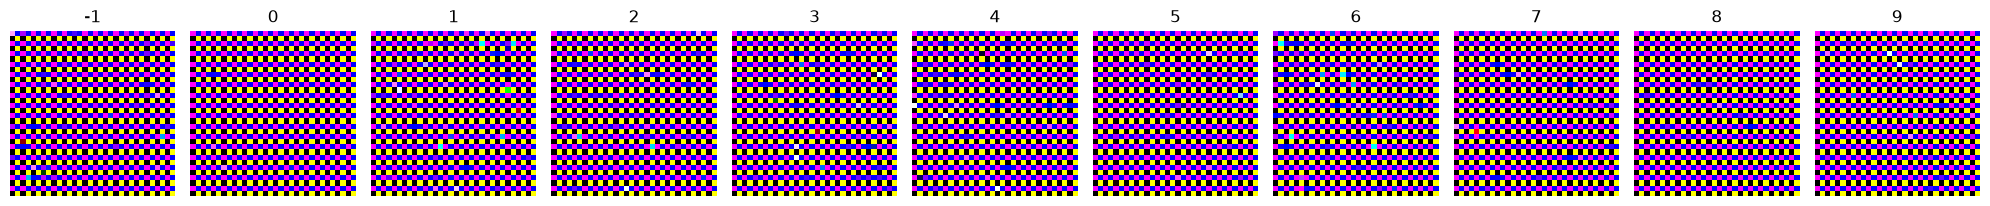

Epoch 66/70
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 7.2630e-04 - learning_rate: 0.0041
Epoch 67/70
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 7.2715e-04 - learning_rate: 0.0041
Epoch 68/70
390/390 ━━━━━━━━━━━━━━━━━━━━ 10s 26ms/step - noise_loss: 7.3435e-04 - learning_rate: 0.0041
Epoch 69/70
390/390 ━━━━━━━━━━━━━━━━━━━━ 10s 25ms/step - noise_loss: 7.3287e-04 - learning_rate: 0.0041
Epoch 70/70
390/390 ━━━━━━━━━━━━━━━━━━━━ 30s 77ms/step - noise_loss: 7.3020e-04 - val_image_loss: 19.1187 - val_loss: 4.2492 - val_noise_loss: 4.2492 - learning_rate: 0.0040
Steps: 50/50


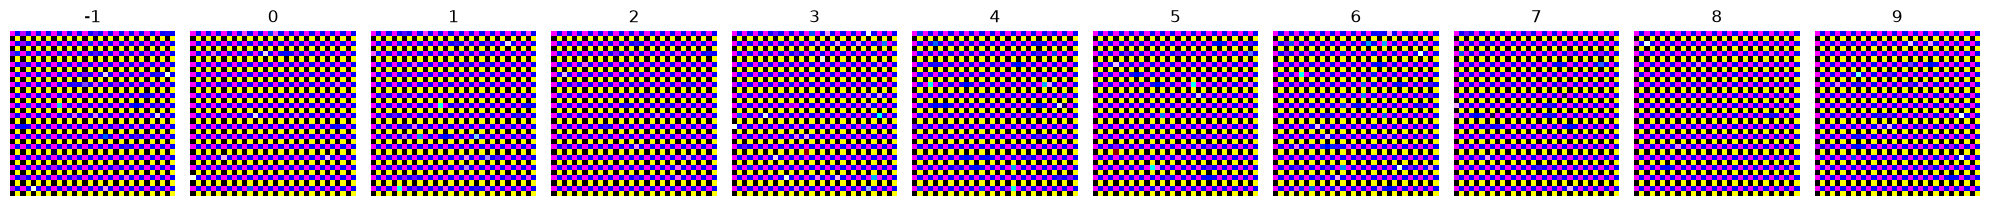

Progressive stage 8/25: changes={'timesteps': (932, 1000)}, resolution=32, sampling t in [932, 1000) range.
Epoch 71/80
390/390 ━━━━━━━━━━━━━━━━━━━━ 31s 30ms/step - noise_loss: 0.0012 - learning_rate: 0.0040
Epoch 72/80
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 9.6360e-04 - learning_rate: 0.0040
Epoch 73/80
390/390 ━━━━━━━━━━━━━━━━━━━━ 10s 26ms/step - noise_loss: 9.8505e-04 - learning_rate: 0.0040
Epoch 74/80
390/390 ━━━━━━━━━━━━━━━━━━━━ 10s 25ms/step - noise_loss: 9.8246e-04 - learning_rate: 0.0039
Epoch 75/80
390/390 ━━━━━━━━━━━━━━━━━━━━ 29s 73ms/step - noise_loss: 9.8188e-04 - val_image_loss: 19.1311 - val_loss: 4.3124 - val_noise_loss: 4.3124 - learning_rate: 0.0039
Steps: 50/50


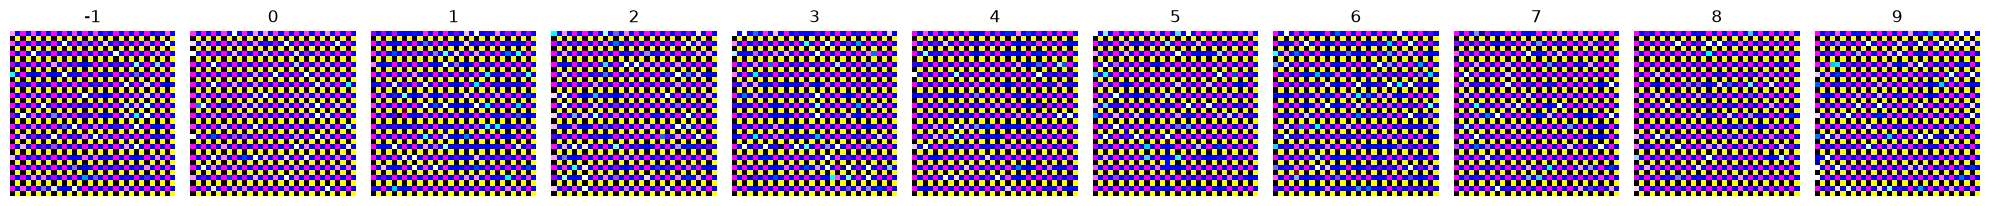

Epoch 76/80
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 48ms/step - noise_loss: 9.7422e-04 - learning_rate: 0.0039
Epoch 77/80
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 49ms/step - noise_loss: 9.9084e-04 - learning_rate: 0.0039
Epoch 78/80
390/390 ━━━━━━━━━━━━━━━━━━━━ 12s 32ms/step - noise_loss: 9.7706e-04 - learning_rate: 0.0038
Epoch 79/80
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 29ms/step - noise_loss: 9.7636e-04 - learning_rate: 0.0038
Epoch 80/80
390/390 ━━━━━━━━━━━━━━━━━━━━ 24s 60ms/step - noise_loss: 9.6465e-04 - val_image_loss: 19.7049 - val_loss: 4.3553 - val_noise_loss: 4.3553 - learning_rate: 0.0038
Steps: 50/50


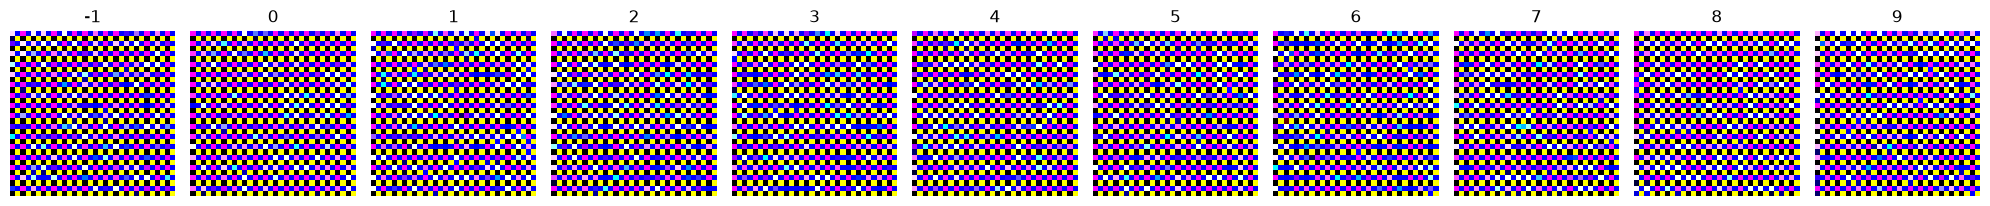

Progressive stage 9/25: changes={'timesteps': (914, 1000)}, resolution=32, sampling t in [914, 1000) range.
Epoch 81/90
390/390 ━━━━━━━━━━━━━━━━━━━━ 38s 49ms/step - noise_loss: 0.0017 - learning_rate: 0.0038
Epoch 82/90
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 48ms/step - noise_loss: 0.0013 - learning_rate: 0.0038
Epoch 83/90
390/390 ━━━━━━━━━━━━━━━━━━━━ 13s 34ms/step - noise_loss: 0.0013 - learning_rate: 0.0037
Epoch 84/90
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 29ms/step - noise_loss: 0.0013 - learning_rate: 0.0037
Epoch 85/90
390/390 ━━━━━━━━━━━━━━━━━━━━ 24s 61ms/step - noise_loss: 0.0013 - val_image_loss: 1.0669 - val_loss: 0.7907 - val_noise_loss: 0.7907 - learning_rate: 0.0037
Steps: 50/50


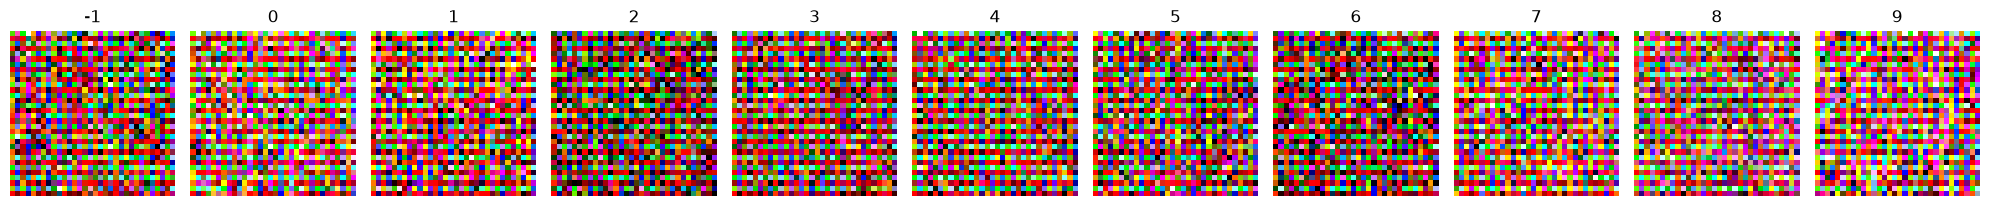

Epoch 86/90
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 48ms/step - noise_loss: 0.0013 - learning_rate: 0.0037
Epoch 87/90
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 49ms/step - noise_loss: 0.0013 - learning_rate: 0.0036
Epoch 88/90
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 50ms/step - noise_loss: 0.0013 - learning_rate: 0.0036
Epoch 89/90
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 48ms/step - noise_loss: 0.0013 - learning_rate: 0.0036
Epoch 90/90
390/390 ━━━━━━━━━━━━━━━━━━━━ 27s 70ms/step - noise_loss: 0.0013 - val_image_loss: 1.1110 - val_loss: 0.8394 - val_noise_loss: 0.8394 - learning_rate: 0.0035
Steps: 50/50


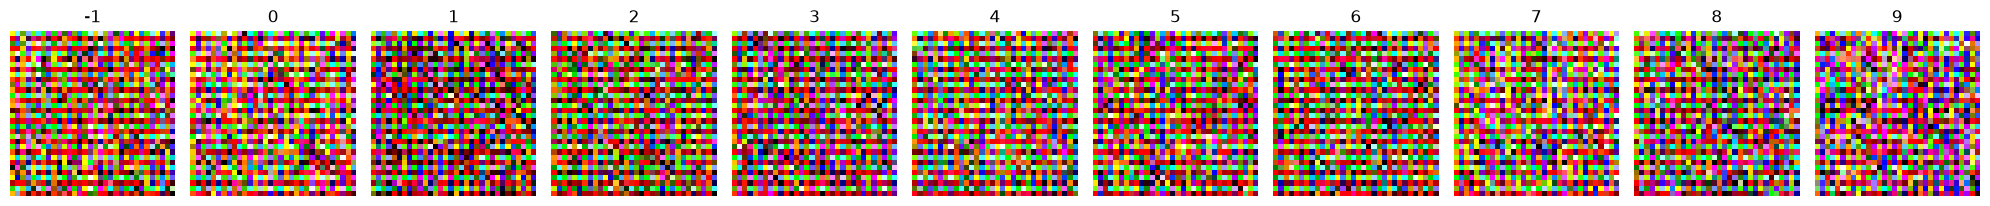

Progressive stage 10/25: changes={'timesteps': (892, 1000)}, resolution=32, sampling t in [892, 1000) range.
Epoch 91/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 38s 47ms/step - noise_loss: 0.0088 - learning_rate: 0.0035
Epoch 92/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 18s 47ms/step - noise_loss: 0.0018 - learning_rate: 0.0035
Epoch 93/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 18s 47ms/step - noise_loss: 0.0018 - learning_rate: 0.0035
Epoch 94/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 48ms/step - noise_loss: 0.0017 - learning_rate: 0.0034
Epoch 95/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 30s 76ms/step - noise_loss: 0.0017 - val_image_loss: 0.8695 - val_loss: 0.7834 - val_noise_loss: 0.7834 - learning_rate: 0.0034
Steps: 50/50


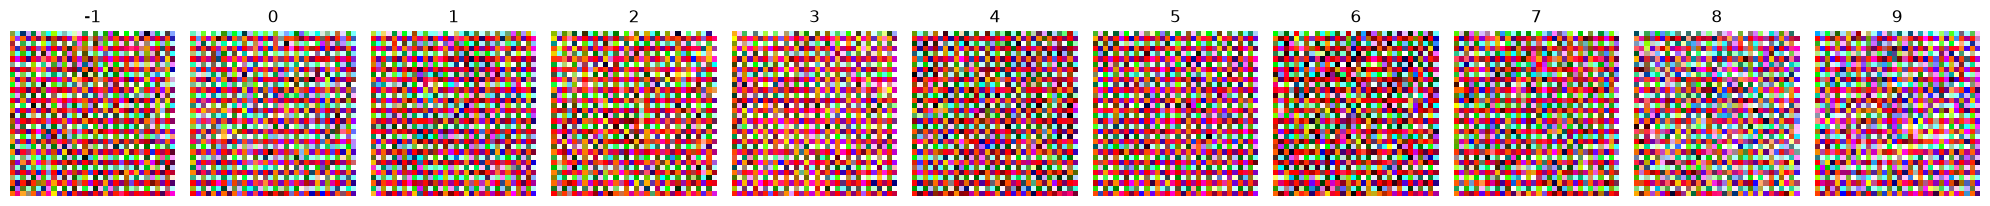

Epoch 96/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 10s 25ms/step - noise_loss: 0.0017 - learning_rate: 0.0034
Epoch 97/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 12s 31ms/step - noise_loss: 0.0017 - learning_rate: 0.0034
Epoch 98/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 48ms/step - noise_loss: 0.0017 - learning_rate: 0.0033
Epoch 99/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 49ms/step - noise_loss: 0.0017 - learning_rate: 0.0033
Epoch 100/100
390/390 ━━━━━━━━━━━━━━━━━━━━ 111s 286ms/step - noise_loss: 0.0017 - val_image_loss: 0.9041 - val_loss: 0.7540 - val_noise_loss: 0.7540 - learning_rate: 0.0033
Steps: 50/50


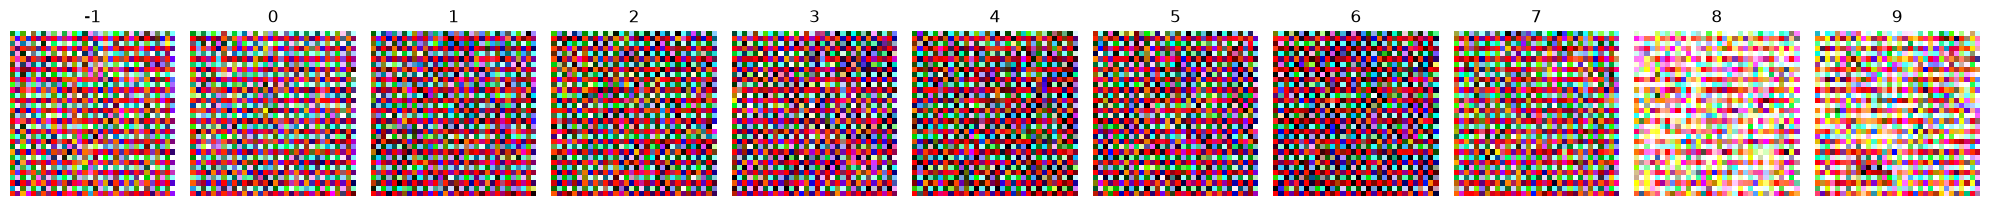

Progressive stage 11/25: changes={'timesteps': (865, 1000)}, resolution=32, sampling t in [865, 1000) range.
Epoch 101/110
390/390 ━━━━━━━━━━━━━━━━━━━━ 37s 25ms/step - noise_loss: 0.0029 - learning_rate: 0.0033
Epoch 102/110
390/390 ━━━━━━━━━━━━━━━━━━━━ 10s 25ms/step - noise_loss: 0.0023 - learning_rate: 0.0032
Epoch 103/110
390/390 ━━━━━━━━━━━━━━━━━━━━ 10s 25ms/step - noise_loss: 0.0023 - learning_rate: 0.0032
Epoch 104/110
390/390 ━━━━━━━━━━━━━━━━━━━━ 10s 25ms/step - noise_loss: 0.0023 - learning_rate: 0.0032
Epoch 105/110
390/390 ━━━━━━━━━━━━━━━━━━━━ 63s 162ms/step - noise_loss: 0.0023 - val_image_loss: 0.4560 - val_loss: 0.6518 - val_noise_loss: 0.6518 - learning_rate: 0.0031
Steps: 50/50


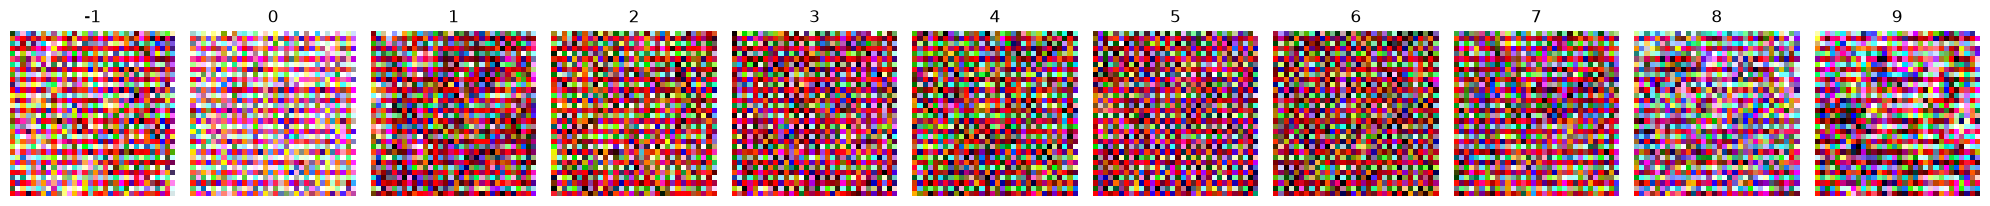

Epoch 106/110
390/390 ━━━━━━━━━━━━━━━━━━━━ 10s 25ms/step - noise_loss: 0.0023 - learning_rate: 0.0031
Epoch 107/110
390/390 ━━━━━━━━━━━━━━━━━━━━ 10s 25ms/step - noise_loss: 0.0023 - learning_rate: 0.0031
Epoch 108/110
390/390 ━━━━━━━━━━━━━━━━━━━━ 10s 25ms/step - noise_loss: 0.0023 - learning_rate: 0.0031
Epoch 109/110
390/390 ━━━━━━━━━━━━━━━━━━━━ 10s 25ms/step - noise_loss: 0.0023 - learning_rate: 0.0030
Epoch 110/110
390/390 ━━━━━━━━━━━━━━━━━━━━ 30s 78ms/step - noise_loss: 0.0023 - val_image_loss: 0.4417 - val_loss: 0.5950 - val_noise_loss: 0.5950 - learning_rate: 0.0030
Steps: 50/50


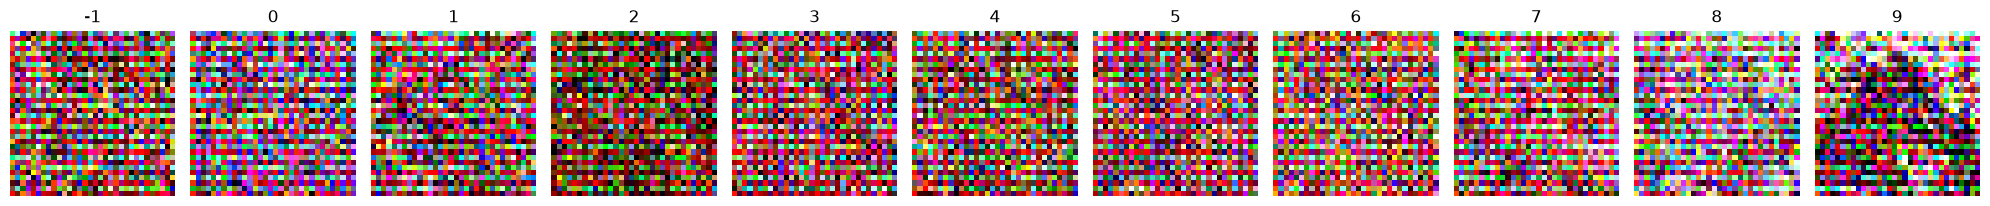

Progressive stage 12/25: changes={'timesteps': (833, 1000)}, resolution=32, sampling t in [833, 1000) range.
Epoch 111/120
390/390 ━━━━━━━━━━━━━━━━━━━━ 31s 31ms/step - noise_loss: 0.0031 - learning_rate: 0.0030
Epoch 112/120
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 0.0030 - learning_rate: 0.0029
Epoch 113/120
390/390 ━━━━━━━━━━━━━━━━━━━━ 10s 27ms/step - noise_loss: 0.0030 - learning_rate: 0.0029
Epoch 114/120
390/390 ━━━━━━━━━━━━━━━━━━━━ 10s 25ms/step - noise_loss: 0.0030 - learning_rate: 0.0029
Epoch 115/120
390/390 ━━━━━━━━━━━━━━━━━━━━ 29s 75ms/step - noise_loss: 0.0029 - val_image_loss: 0.3383 - val_loss: 0.4800 - val_noise_loss: 0.4800 - learning_rate: 0.0029
Steps: 50/50


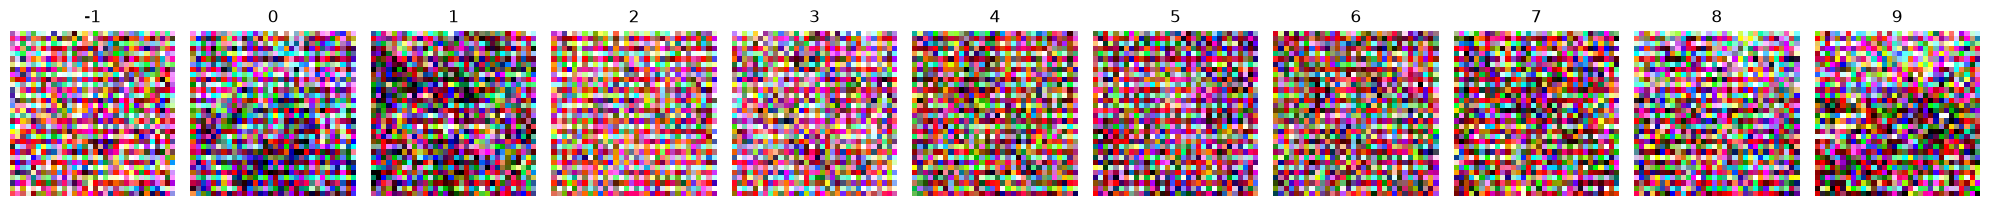

Epoch 116/120
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 48ms/step - noise_loss: 0.0029 - learning_rate: 0.0028
Epoch 117/120
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 48ms/step - noise_loss: 0.0029 - learning_rate: 0.0028
Epoch 118/120
390/390 ━━━━━━━━━━━━━━━━━━━━ 12s 31ms/step - noise_loss: 0.0029 - learning_rate: 0.0028
Epoch 119/120
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0029 - learning_rate: 0.0027
Epoch 120/120
390/390 ━━━━━━━━━━━━━━━━━━━━ 24s 60ms/step - noise_loss: 0.0029 - val_image_loss: 0.3186 - val_loss: 0.4635 - val_noise_loss: 0.4635 - learning_rate: 0.0027
Steps: 50/50


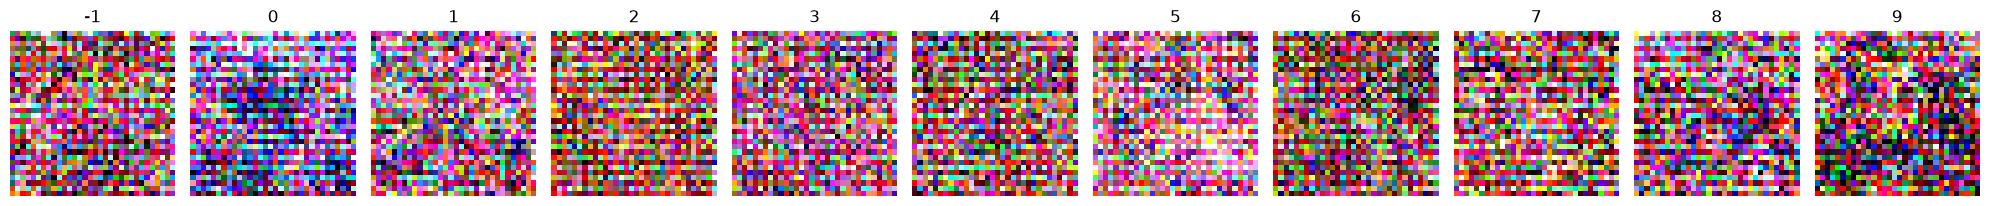

Progressive stage 13/25: changes={'timesteps': (794, 1000)}, resolution=32, sampling t in [794, 1000) range.
Epoch 121/130
390/390 ━━━━━━━━━━━━━━━━━━━━ 38s 48ms/step - noise_loss: 0.0040 - learning_rate: 0.0027
Epoch 122/130
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 48ms/step - noise_loss: 0.0038 - learning_rate: 0.0027
Epoch 123/130
390/390 ━━━━━━━━━━━━━━━━━━━━ 14s 35ms/step - noise_loss: 0.0038 - learning_rate: 0.0026
Epoch 124/130
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0038 - learning_rate: 0.0026
Epoch 125/130
390/390 ━━━━━━━━━━━━━━━━━━━━ 24s 61ms/step - noise_loss: 0.0038 - val_image_loss: 0.2591 - val_loss: 0.4472 - val_noise_loss: 0.4472 - learning_rate: 0.0026
Steps: 50/50


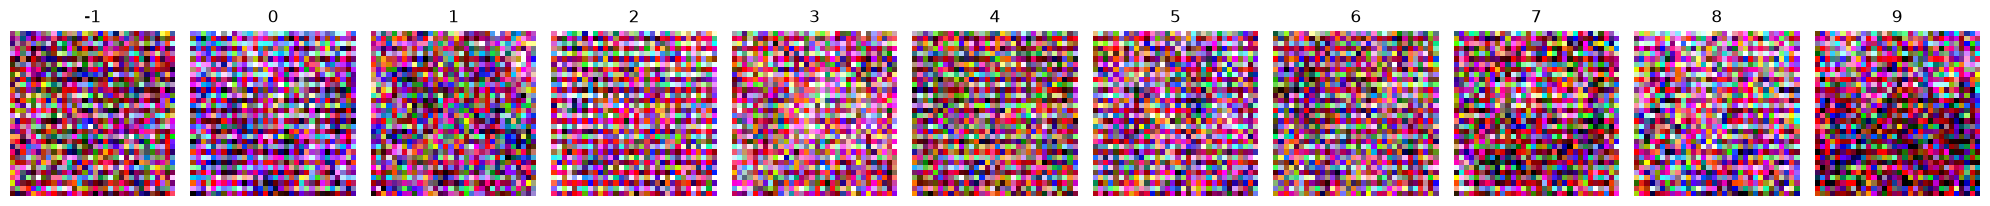

Epoch 126/130
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 49ms/step - noise_loss: 0.0038 - learning_rate: 0.0025
Epoch 127/130
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 47ms/step - noise_loss: 0.0038 - learning_rate: 0.0025
Epoch 128/130
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 48ms/step - noise_loss: 0.0038 - learning_rate: 0.0025
Epoch 129/130
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 48ms/step - noise_loss: 0.0038 - learning_rate: 0.0025
Epoch 130/130
390/390 ━━━━━━━━━━━━━━━━━━━━ 28s 73ms/step - noise_loss: 0.0038 - val_image_loss: 0.2698 - val_loss: 0.4791 - val_noise_loss: 0.4791 - learning_rate: 0.0024
Steps: 50/50


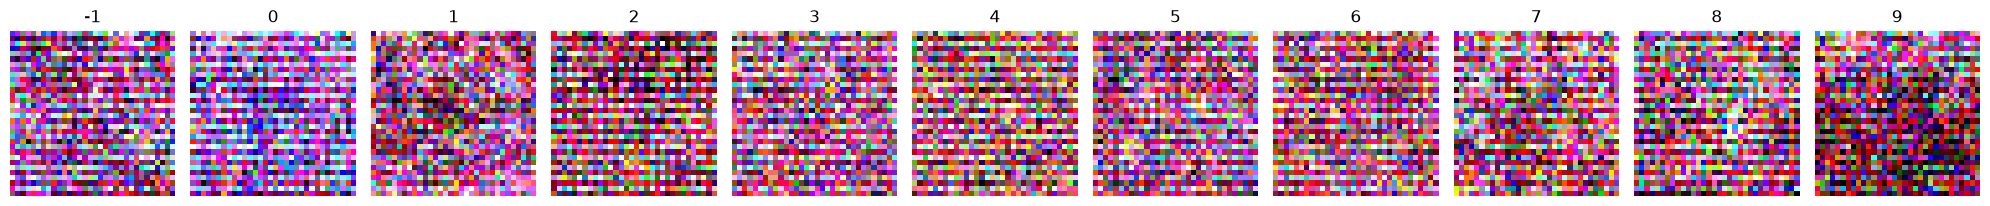

Progressive stage 14/25: changes={'timesteps': (749, 1000)}, resolution=32, sampling t in [749, 1000) range.
Epoch 131/140
390/390 ━━━━━━━━━━━━━━━━━━━━ 37s 48ms/step - noise_loss: 0.0050 - learning_rate: 0.0024
Epoch 132/140
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 49ms/step - noise_loss: 0.0049 - learning_rate: 0.0024
Epoch 133/140
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 49ms/step - noise_loss: 0.0049 - learning_rate: 0.0023
Epoch 134/140
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 49ms/step - noise_loss: 0.0048 - learning_rate: 0.0023
Epoch 135/140
390/390 ━━━━━━━━━━━━━━━━━━━━ 31s 79ms/step - noise_loss: 0.0048 - val_image_loss: 0.2723 - val_loss: 0.5433 - val_noise_loss: 0.5433 - learning_rate: 0.0023
Steps: 50/50


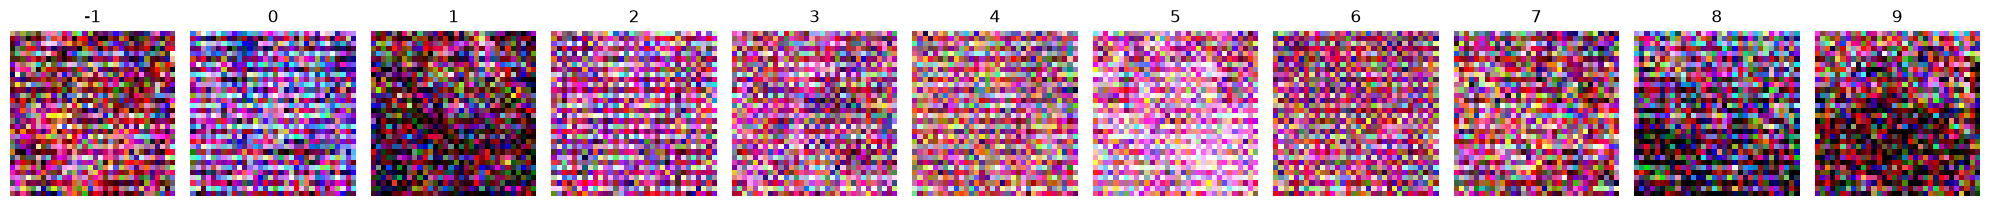

Epoch 136/140
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 48ms/step - noise_loss: 0.0048 - learning_rate: 0.0022
Epoch 137/140
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 49ms/step - noise_loss: 0.0047 - learning_rate: 0.0022
Epoch 140/140
390/390 ━━━━━━━━━━━━━━━━━━━━ 32s 83ms/step - noise_loss: 0.0047 - val_image_loss: 0.2844 - val_loss: 0.5630 - val_noise_loss: 0.5630 - learning_rate: 0.0021
Steps: 50/50


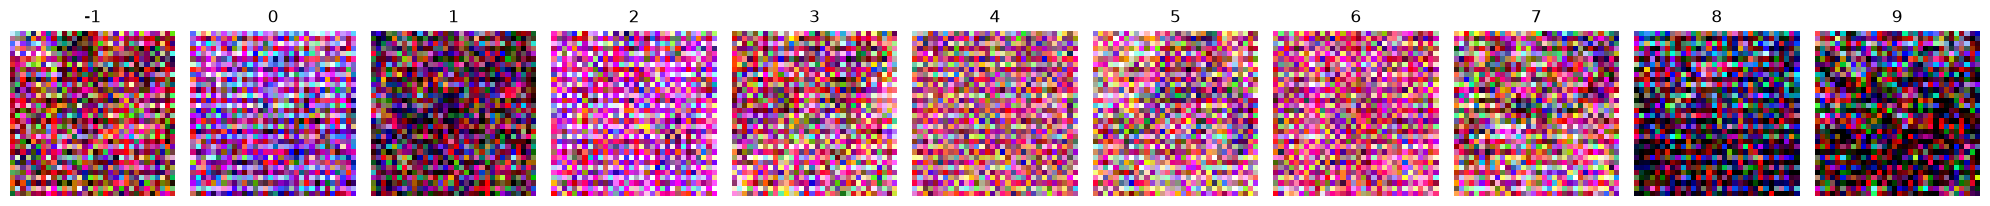

Progressive stage 15/25: changes={'timesteps': (695, 1000)}, resolution=32, sampling t in [695, 1000) range.
Epoch 141/150
390/390 ━━━━━━━━━━━━━━━━━━━━ 30s 29ms/step - noise_loss: 0.0063 - learning_rate: 0.0021
Epoch 142/150
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 29ms/step - noise_loss: 0.0061 - learning_rate: 0.0021
Epoch 143/150
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 29ms/step - noise_loss: 0.0060 - learning_rate: 0.0020
Epoch 144/150
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 29ms/step - noise_loss: 0.0061 - learning_rate: 0.0020
Epoch 145/150
390/390 ━━━━━━━━━━━━━━━━━━━━ 25s 63ms/step - noise_loss: 0.0060 - val_image_loss: 0.3285 - val_loss: 0.6239 - val_noise_loss: 0.6239 - learning_rate: 0.0020
Steps: 50/50


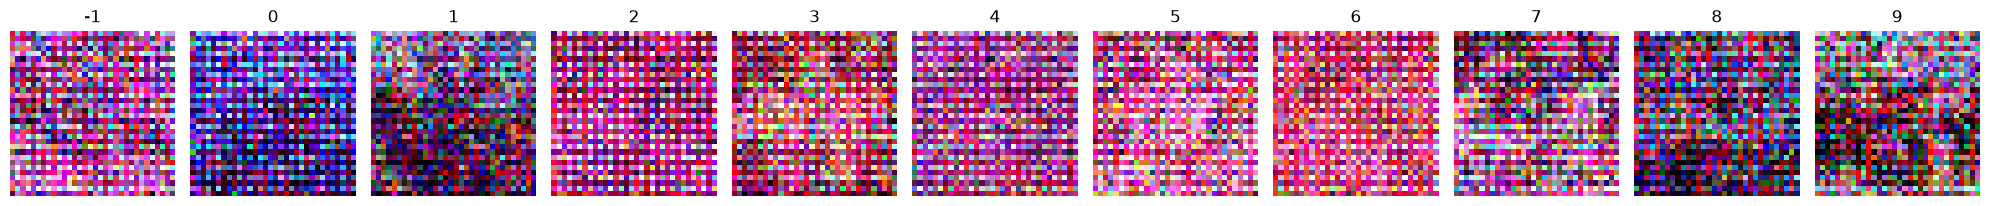

Epoch 146/150
390/390 ━━━━━━━━━━━━━━━━━━━━ 12s 29ms/step - noise_loss: 0.0060 - learning_rate: 0.0020
Epoch 147/150
390/390 ━━━━━━━━━━━━━━━━━━━━ 12s 29ms/step - noise_loss: 0.0060 - learning_rate: 0.0019
Epoch 148/150
390/390 ━━━━━━━━━━━━━━━━━━━━ 12s 29ms/step - noise_loss: 0.0059 - learning_rate: 0.0019
Epoch 149/150
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 29ms/step - noise_loss: 0.0059 - learning_rate: 0.0019
Epoch 150/150
390/390 ━━━━━━━━━━━━━━━━━━━━ 25s 63ms/step - noise_loss: 0.0059 - val_image_loss: 0.2915 - val_loss: 0.5287 - val_noise_loss: 0.5287 - learning_rate: 0.0018
Steps: 50/50


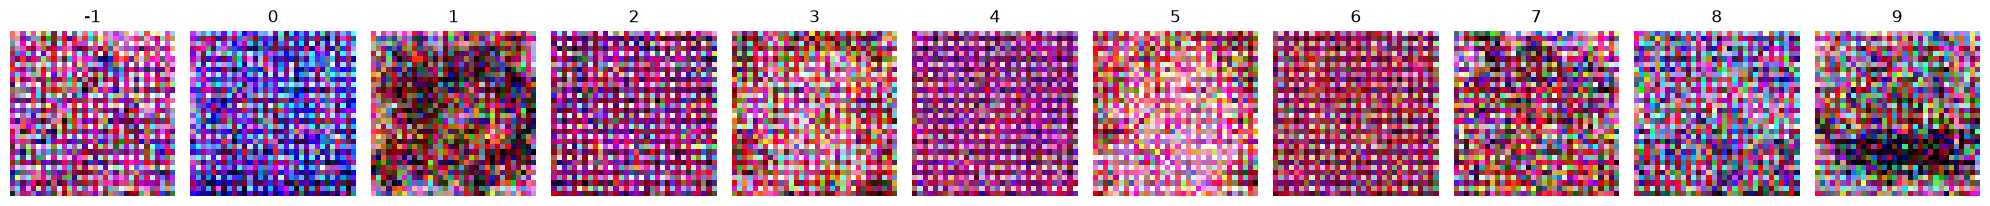

Progressive stage 16/25: changes={'timesteps': (634, 1000)}, resolution=32, sampling t in [634, 1000) range.
Epoch 151/160
390/390 ━━━━━━━━━━━━━━━━━━━━ 31s 29ms/step - noise_loss: 0.0077 - learning_rate: 0.0018
Epoch 152/160
390/390 ━━━━━━━━━━━━━━━━━━━━ 12s 29ms/step - noise_loss: 0.0075 - learning_rate: 0.0018
Epoch 153/160
390/390 ━━━━━━━━━━━━━━━━━━━━ 12s 29ms/step - noise_loss: 0.0075 - learning_rate: 0.0018
Epoch 154/160
390/390 ━━━━━━━━━━━━━━━━━━━━ 12s 29ms/step - noise_loss: 0.0075 - learning_rate: 0.0017
Epoch 155/160
390/390 ━━━━━━━━━━━━━━━━━━━━ 25s 63ms/step - noise_loss: 0.0074 - val_image_loss: 0.1941 - val_loss: 0.3845 - val_noise_loss: 0.3845 - learning_rate: 0.0017
Steps: 50/50


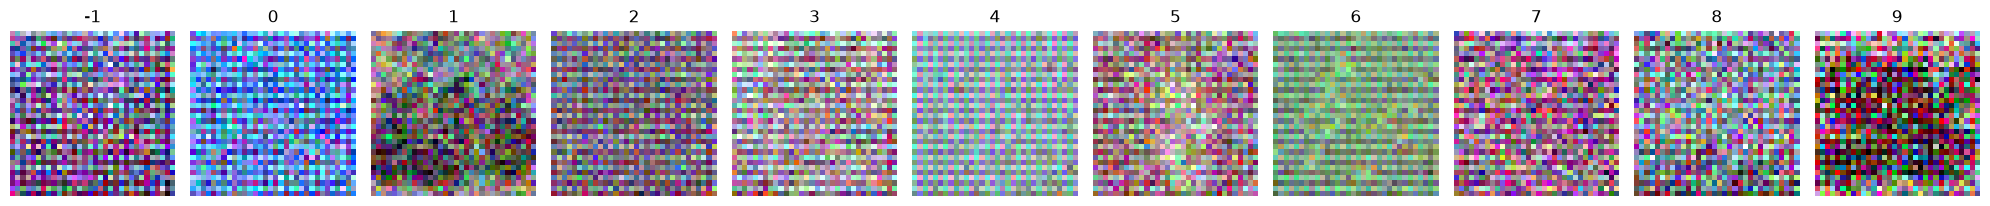

Epoch 156/160
390/390 ━━━━━━━━━━━━━━━━━━━━ 12s 29ms/step - noise_loss: 0.0074 - learning_rate: 0.0017
Epoch 157/160
390/390 ━━━━━━━━━━━━━━━━━━━━ 12s 30ms/step - noise_loss: 0.0074 - learning_rate: 0.0016
Epoch 158/160
390/390 ━━━━━━━━━━━━━━━━━━━━ 12s 29ms/step - noise_loss: 0.0074 - learning_rate: 0.0016
Epoch 159/160
390/390 ━━━━━━━━━━━━━━━━━━━━ 12s 29ms/step - noise_loss: 0.0073 - learning_rate: 0.0016
Epoch 160/160
390/390 ━━━━━━━━━━━━━━━━━━━━ 25s 63ms/step - noise_loss: 0.0073 - val_image_loss: 0.2034 - val_loss: 0.4305 - val_noise_loss: 0.4305 - learning_rate: 0.0016
Steps: 50/50


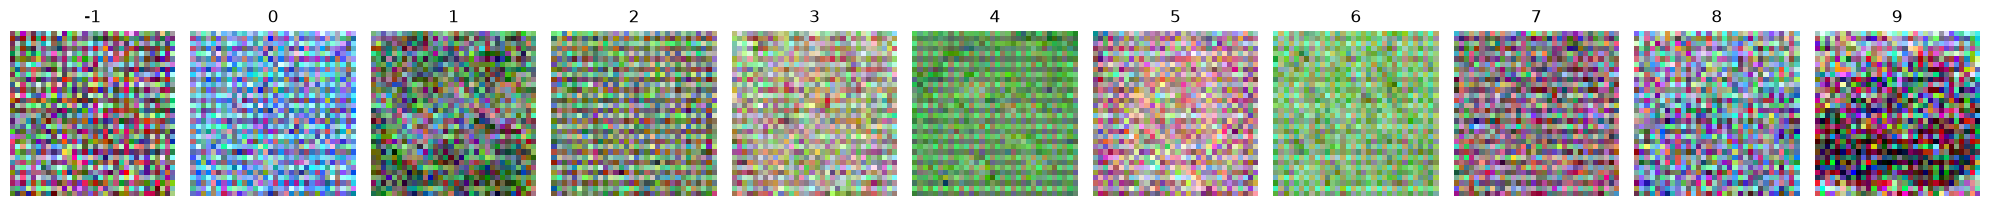

Progressive stage 17/25: changes={'timesteps': (565, 1000)}, resolution=32, sampling t in [565, 1000) range.
Epoch 161/170
390/390 ━━━━━━━━━━━━━━━━━━━━ 30s 29ms/step - noise_loss: 0.0092 - learning_rate: 0.0015
Epoch 162/170
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 29ms/step - noise_loss: 0.0092 - learning_rate: 0.0015
Epoch 163/170
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 29ms/step - noise_loss: 0.0091 - learning_rate: 0.0015
Epoch 164/170
390/390 ━━━━━━━━━━━━━━━━━━━━ 10s 25ms/step - noise_loss: 0.0090 - learning_rate: 0.0015
Epoch 165/170
390/390 ━━━━━━━━━━━━━━━━━━━━ 23s 58ms/step - noise_loss: 0.0090 - val_image_loss: 0.2847 - val_loss: 0.6964 - val_noise_loss: 0.6964 - learning_rate: 0.0014
Steps: 50/50


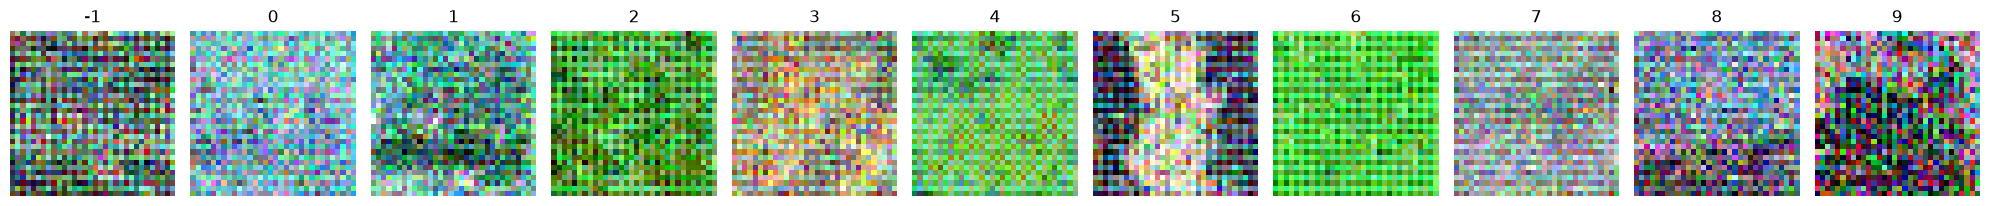

Epoch 166/170
390/390 ━━━━━━━━━━━━━━━━━━━━ 10s 25ms/step - noise_loss: 0.0089 - learning_rate: 0.0014
Epoch 167/170
390/390 ━━━━━━━━━━━━━━━━━━━━ 10s 25ms/step - noise_loss: 0.0090 - learning_rate: 0.0014
Epoch 168/170
390/390 ━━━━━━━━━━━━━━━━━━━━ 10s 25ms/step - noise_loss: 0.0089 - learning_rate: 0.0013
Epoch 169/170
390/390 ━━━━━━━━━━━━━━━━━━━━ 10s 25ms/step - noise_loss: 0.0089 - learning_rate: 0.0013
Epoch 170/170
390/390 ━━━━━━━━━━━━━━━━━━━━ 23s 58ms/step - noise_loss: 0.0088 - val_image_loss: 0.3303 - val_loss: 0.7961 - val_noise_loss: 0.7961 - learning_rate: 0.0013
Steps: 50/50


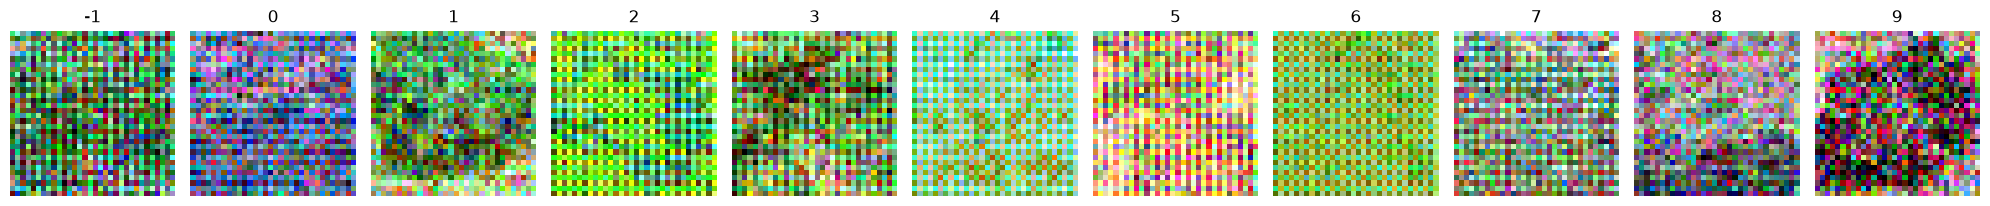

Progressive stage 18/25: changes={'timesteps': (490, 1000)}, resolution=32, sampling t in [490, 1000) range.
Epoch 171/180
390/390 ━━━━━━━━━━━━━━━━━━━━ 28s 25ms/step - noise_loss: 0.0111 - learning_rate: 0.0013
Epoch 172/180
390/390 ━━━━━━━━━━━━━━━━━━━━ 10s 25ms/step - noise_loss: 0.0109 - learning_rate: 0.0012
Epoch 173/180
390/390 ━━━━━━━━━━━━━━━━━━━━ 10s 25ms/step - noise_loss: 0.0110 - learning_rate: 0.0012
Epoch 174/180
390/390 ━━━━━━━━━━━━━━━━━━━━ 10s 25ms/step - noise_loss: 0.0110 - learning_rate: 0.0012
Epoch 175/180
390/390 ━━━━━━━━━━━━━━━━━━━━ 23s 58ms/step - noise_loss: 0.0109 - val_image_loss: 0.4439 - val_loss: 1.1703 - val_noise_loss: 1.1703 - learning_rate: 0.0012
Steps: 50/50


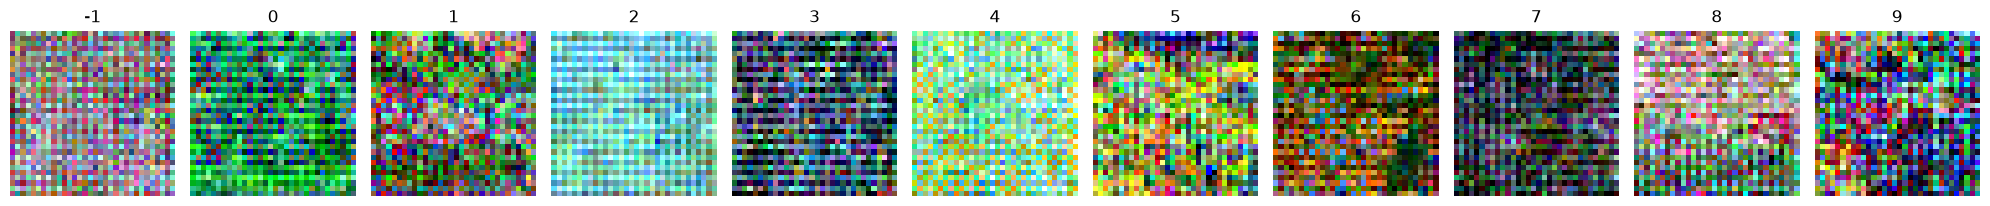

Epoch 176/180
390/390 ━━━━━━━━━━━━━━━━━━━━ 10s 25ms/step - noise_loss: 0.0109 - learning_rate: 0.0011
Epoch 177/180
390/390 ━━━━━━━━━━━━━━━━━━━━ 10s 25ms/step - noise_loss: 0.0109 - learning_rate: 0.0011
Epoch 178/180
390/390 ━━━━━━━━━━━━━━━━━━━━ 10s 25ms/step - noise_loss: 0.0109 - learning_rate: 0.0011
Epoch 179/180
390/390 ━━━━━━━━━━━━━━━━━━━━ 10s 25ms/step - noise_loss: 0.0109 - learning_rate: 0.0011
Epoch 180/180
390/390 ━━━━━━━━━━━━━━━━━━━━ 23s 58ms/step - noise_loss: 0.0109 - val_image_loss: 0.4569 - val_loss: 1.0735 - val_noise_loss: 1.0735 - learning_rate: 0.0010
Steps: 50/50


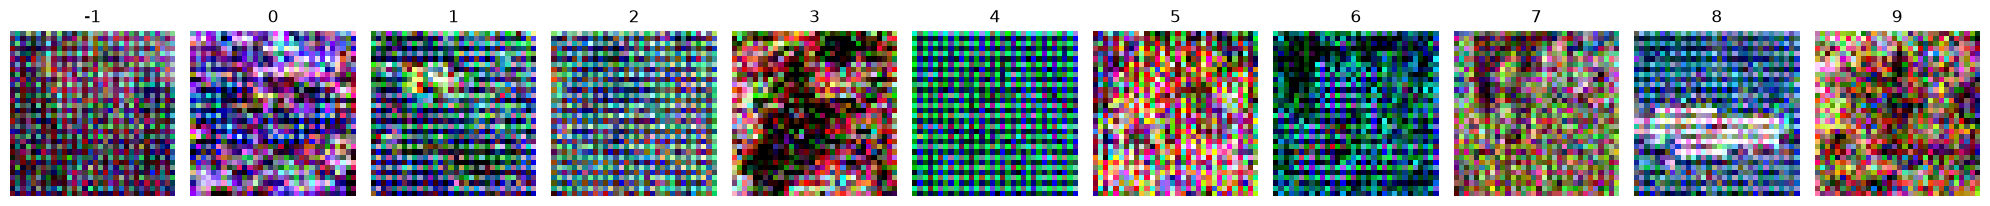

Progressive stage 19/25: changes={'timesteps': (411, 1000)}, resolution=32, sampling t in [411, 1000) range.
Epoch 181/190
390/390 ━━━━━━━━━━━━━━━━━━━━ 29s 25ms/step - noise_loss: 0.0133 - learning_rate: 0.0010
Epoch 182/190
390/390 ━━━━━━━━━━━━━━━━━━━━ 10s 25ms/step - noise_loss: 0.0133 - learning_rate: 9.9859e-04
Epoch 183/190
390/390 ━━━━━━━━━━━━━━━━━━━━ 10s 25ms/step - noise_loss: 0.0132 - learning_rate: 9.7502e-04
Epoch 184/190
390/390 ━━━━━━━━━━━━━━━━━━━━ 10s 25ms/step - noise_loss: 0.0131 - learning_rate: 9.5165e-04
Epoch 185/190
390/390 ━━━━━━━━━━━━━━━━━━━━ 23s 58ms/step - noise_loss: 0.0132 - val_image_loss: 0.3178 - val_loss: 0.9728 - val_noise_loss: 0.9728 - learning_rate: 9.2850e-04
Steps: 50/50


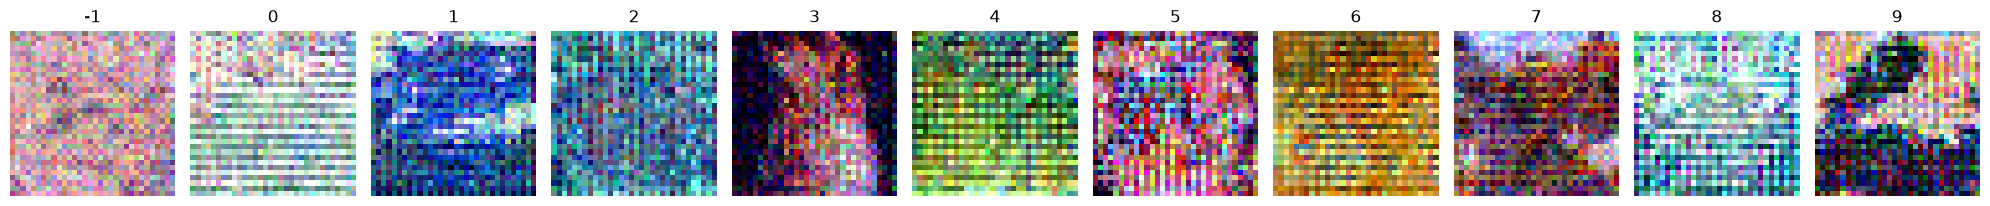

Epoch 186/190
390/390 ━━━━━━━━━━━━━━━━━━━━ 10s 25ms/step - noise_loss: 0.0132 - learning_rate: 9.0557e-04
Epoch 187/190
390/390 ━━━━━━━━━━━━━━━━━━━━ 10s 25ms/step - noise_loss: 0.0131 - learning_rate: 8.8286e-04
Epoch 188/190
390/390 ━━━━━━━━━━━━━━━━━━━━ 10s 25ms/step - noise_loss: 0.0131 - learning_rate: 8.6037e-04
Epoch 189/190
390/390 ━━━━━━━━━━━━━━━━━━━━ 10s 25ms/step - noise_loss: 0.0130 - learning_rate: 8.3811e-04
Epoch 190/190
390/390 ━━━━━━━━━━━━━━━━━━━━ 23s 59ms/step - noise_loss: 0.0131 - val_image_loss: 0.3089 - val_loss: 0.9539 - val_noise_loss: 0.9539 - learning_rate: 8.1609e-04
Steps: 50/50


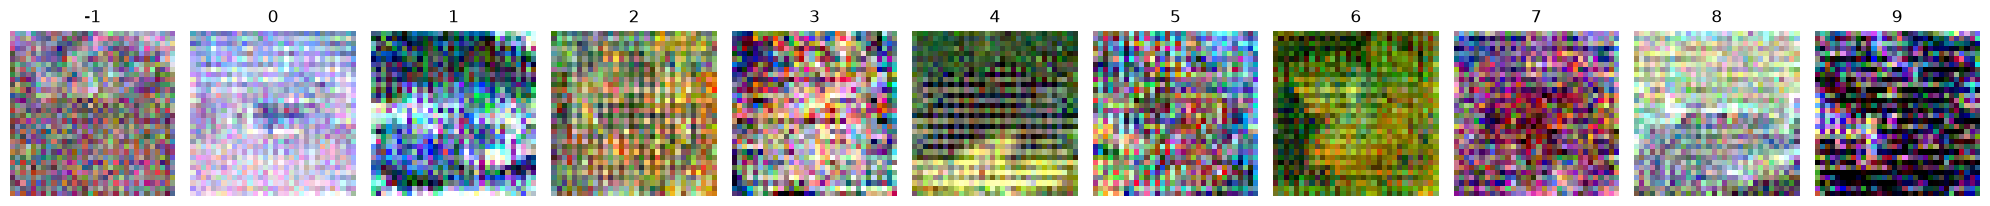

Progressive stage 20/25: changes={'timesteps': (331, 1000)}, resolution=32, sampling t in [331, 1000) range.
Epoch 191/200
390/390 ━━━━━━━━━━━━━━━━━━━━ 29s 25ms/step - noise_loss: 0.0158 - learning_rate: 7.9429e-04
Epoch 192/200
390/390 ━━━━━━━━━━━━━━━━━━━━ 10s 25ms/step - noise_loss: 0.0157 - learning_rate: 7.7274e-04
Epoch 193/200
390/390 ━━━━━━━━━━━━━━━━━━━━ 14s 37ms/step - noise_loss: 0.0157 - learning_rate: 7.5143e-04
Epoch 194/200
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0156 - learning_rate: 7.3036e-04
Epoch 195/200
390/390 ━━━━━━━━━━━━━━━━━━━━ 32s 83ms/step - noise_loss: 0.0157 - val_image_loss: 0.2554 - val_loss: 0.8066 - val_noise_loss: 0.8066 - learning_rate: 7.0954e-04
Steps: 50/50


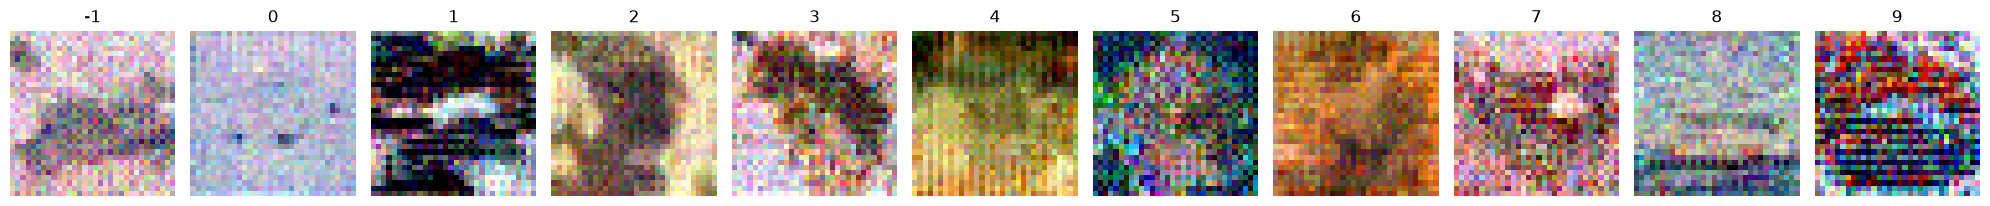

Epoch 196/200
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 49ms/step - noise_loss: 0.0156 - learning_rate: 6.8896e-04
Epoch 197/200
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 49ms/step - noise_loss: 0.0156 - learning_rate: 6.6864e-04
Epoch 198/200
390/390 ━━━━━━━━━━━━━━━━━━━━ 12s 30ms/step - noise_loss: 0.0155 - learning_rate: 6.4858e-04
Epoch 199/200
390/390 ━━━━━━━━━━━━━━━━━━━━ 10s 25ms/step - noise_loss: 0.0155 - learning_rate: 6.2878e-04
Epoch 200/200
390/390 ━━━━━━━━━━━━━━━━━━━━ 27s 68ms/step - noise_loss: 0.0155 - val_image_loss: 0.2250 - val_loss: 0.6824 - val_noise_loss: 0.6824 - learning_rate: 6.0923e-04
Steps: 50/50


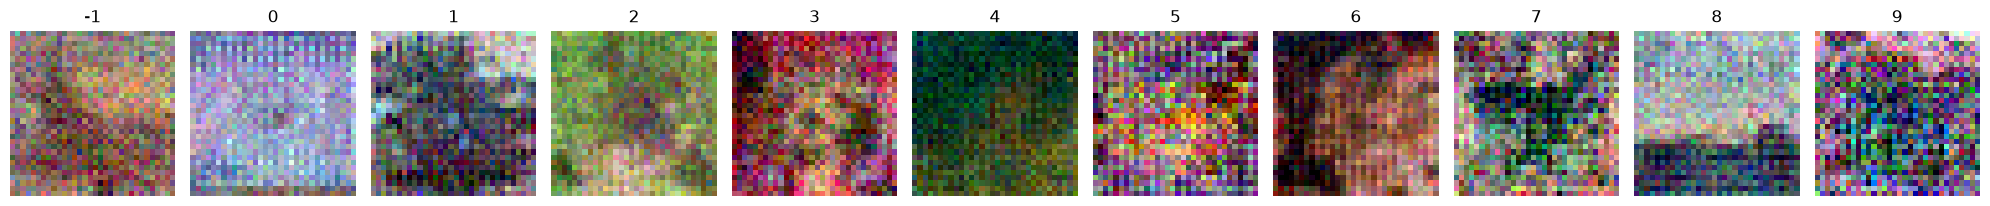

Progressive stage 21/25: changes={'timesteps': (252, 1000)}, resolution=32, sampling t in [252, 1000) range.
Epoch 201/210
390/390 ━━━━━━━━━━━━━━━━━━━━ 33s 28ms/step - noise_loss: 0.0184 - learning_rate: 5.8996e-04
Epoch 202/210
390/390 ━━━━━━━━━━━━━━━━━━━━ 17s 43ms/step - noise_loss: 0.0183 - learning_rate: 5.7095e-04
Epoch 203/210
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 49ms/step - noise_loss: 0.0184 - learning_rate: 5.5221e-04
Epoch 204/210
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 49ms/step - noise_loss: 0.0184 - learning_rate: 5.3374e-04
Epoch 205/210
390/390 ━━━━━━━━━━━━━━━━━━━━ 34s 87ms/step - noise_loss: 0.0184 - val_image_loss: 0.0916 - val_loss: 0.1357 - val_noise_loss: 0.1357 - learning_rate: 5.1555e-04
Steps: 50/50


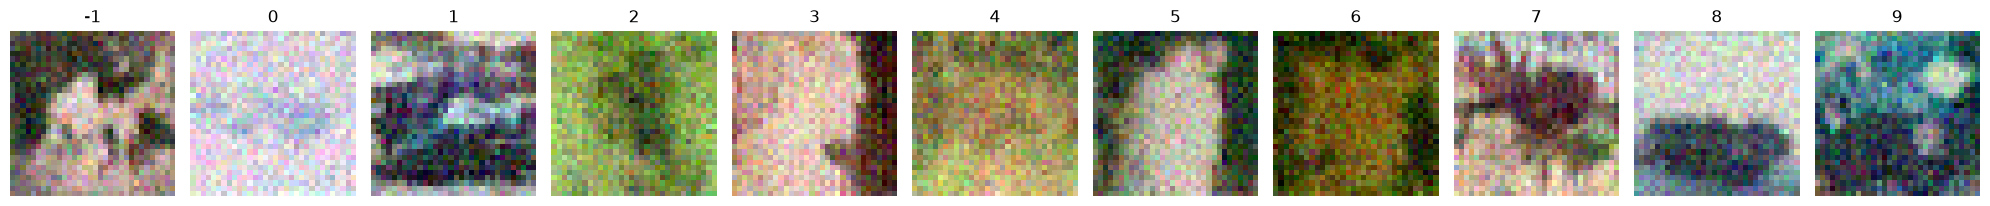

Epoch 206/210
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0183 - learning_rate: 4.9764e-04
Epoch 207/210
390/390 ━━━━━━━━━━━━━━━━━━━━ 17s 45ms/step - noise_loss: 0.0183 - learning_rate: 4.8000e-04
Epoch 208/210
390/390 ━━━━━━━━━━━━━━━━━━━━ 20s 50ms/step - noise_loss: 0.0183 - learning_rate: 4.6266e-04
Epoch 209/210
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 50ms/step - noise_loss: 0.0184 - learning_rate: 4.4560e-04
Epoch 210/210
390/390 ━━━━━━━━━━━━━━━━━━━━ 33s 86ms/step - noise_loss: 0.0183 - val_image_loss: 0.0887 - val_loss: 0.1069 - val_noise_loss: 0.1069 - learning_rate: 4.2882e-04
Steps: 50/50


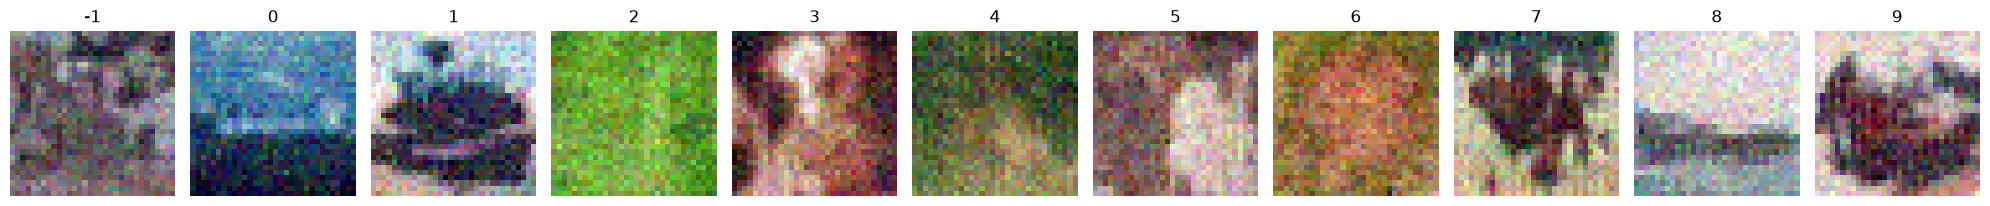

Progressive stage 22/25: changes={'timesteps': (179, 1000)}, resolution=32, sampling t in [179, 1000) range.
Epoch 211/220
390/390 ━━━━━━━━━━━━━━━━━━━━ 39s 49ms/step - noise_loss: 0.0212 - learning_rate: 4.1234e-04
Epoch 212/220
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 49ms/step - noise_loss: 0.0212 - learning_rate: 3.9615e-04
Epoch 213/220
390/390 ━━━━━━━━━━━━━━━━━━━━ 20s 51ms/step - noise_loss: 0.0211 - learning_rate: 3.8026e-04
Epoch 214/220
390/390 ━━━━━━━━━━━━━━━━━━━━ 20s 50ms/step - noise_loss: 0.0210 - learning_rate: 3.6466e-04
Epoch 215/220
390/390 ━━━━━━━━━━━━━━━━━━━━ 27s 68ms/step - noise_loss: 0.0210 - val_image_loss: 0.0783 - val_loss: 0.0484 - val_noise_loss: 0.0484 - learning_rate: 3.4937e-04
Steps: 50/50


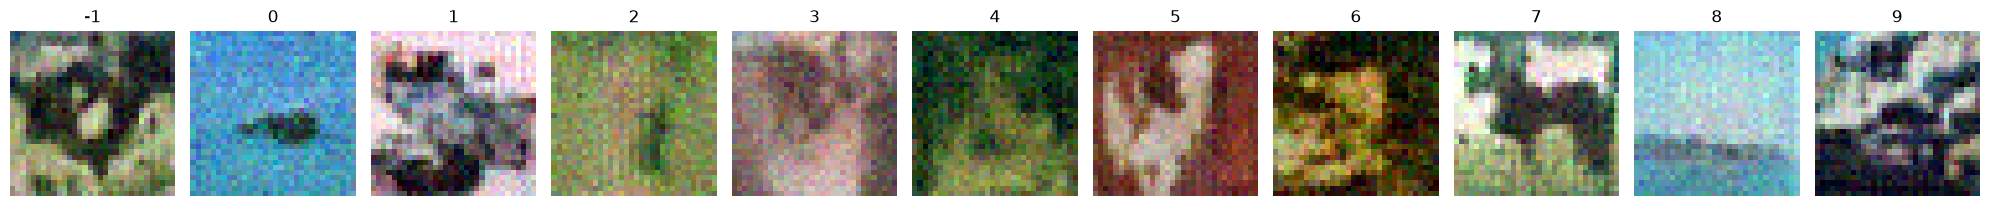

Epoch 216/220
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 49ms/step - noise_loss: 0.0211 - learning_rate: 3.3438e-04
Epoch 217/220
390/390 ━━━━━━━━━━━━━━━━━━━━ 20s 50ms/step - noise_loss: 0.0210 - learning_rate: 3.1969e-04
Epoch 218/220
390/390 ━━━━━━━━━━━━━━━━━━━━ 20s 51ms/step - noise_loss: 0.0212 - learning_rate: 3.0531e-04
Epoch 219/220
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 50ms/step - noise_loss: 0.0211 - learning_rate: 2.9124e-04
Epoch 220/220
390/390 ━━━━━━━━━━━━━━━━━━━━ 27s 69ms/step - noise_loss: 0.0210 - val_image_loss: 0.0784 - val_loss: 0.0460 - val_noise_loss: 0.0460 - learning_rate: 2.7748e-04
Steps: 50/50


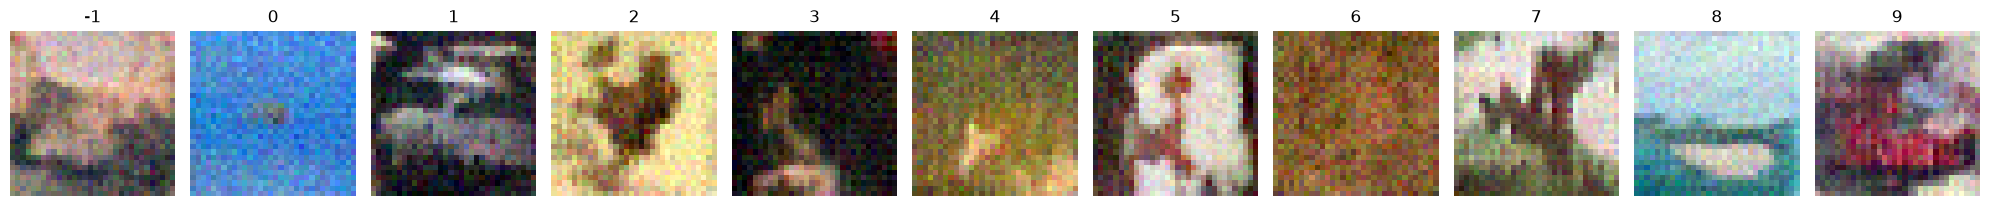

Progressive stage 23/25: changes={'timesteps': (111, 1000)}, resolution=32, sampling t in [111, 1000) range.
Epoch 221/230
390/390 ━━━━━━━━━━━━━━━━━━━━ 39s 49ms/step - noise_loss: 0.0242 - learning_rate: 2.6404e-04
Epoch 222/230
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 50ms/step - noise_loss: 0.0242 - learning_rate: 2.5091e-04
Epoch 223/230
390/390 ━━━━━━━━━━━━━━━━━━━━ 13s 34ms/step - noise_loss: 0.0241 - learning_rate: 2.3809e-04
Epoch 224/230
390/390 ━━━━━━━━━━━━━━━━━━━━ 12s 30ms/step - noise_loss: 0.0240 - learning_rate: 2.2560e-04
Epoch 225/230
390/390 ━━━━━━━━━━━━━━━━━━━━ 30s 77ms/step - noise_loss: 0.0240 - val_image_loss: 0.0769 - val_loss: 0.0366 - val_noise_loss: 0.0366 - learning_rate: 2.1342e-04
Steps: 50/50


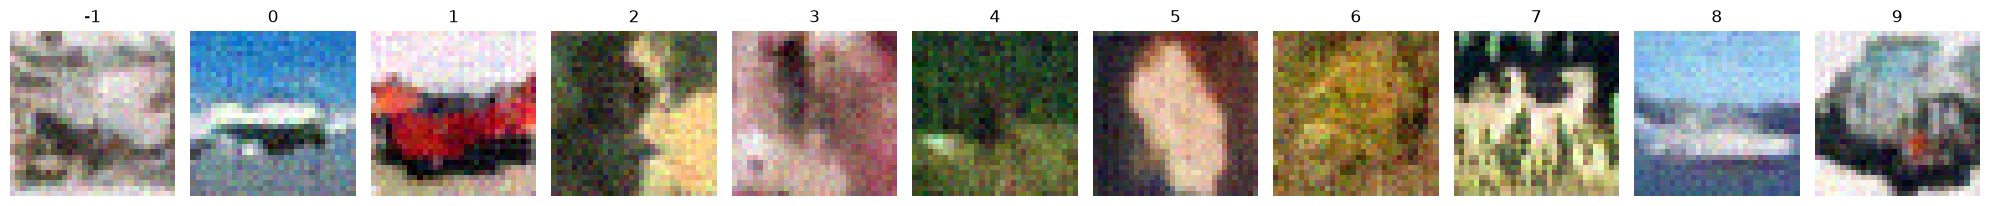

Epoch 226/230
390/390 ━━━━━━━━━━━━━━━━━━━━ 20s 51ms/step - noise_loss: 0.0240 - learning_rate: 2.0157e-04
Epoch 227/230
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 49ms/step - noise_loss: 0.0240 - learning_rate: 1.9004e-04
Epoch 228/230
390/390 ━━━━━━━━━━━━━━━━━━━━ 13s 33ms/step - noise_loss: 0.0240 - learning_rate: 1.7884e-04
Epoch 229/230
390/390 ━━━━━━━━━━━━━━━━━━━━ 12s 30ms/step - noise_loss: 0.0238 - learning_rate: 1.6797e-04
Epoch 230/230
390/390 ━━━━━━━━━━━━━━━━━━━━ 32s 82ms/step - noise_loss: 0.0240 - val_image_loss: 0.0762 - val_loss: 0.0364 - val_noise_loss: 0.0364 - learning_rate: 1.5742e-04
Steps: 50/50


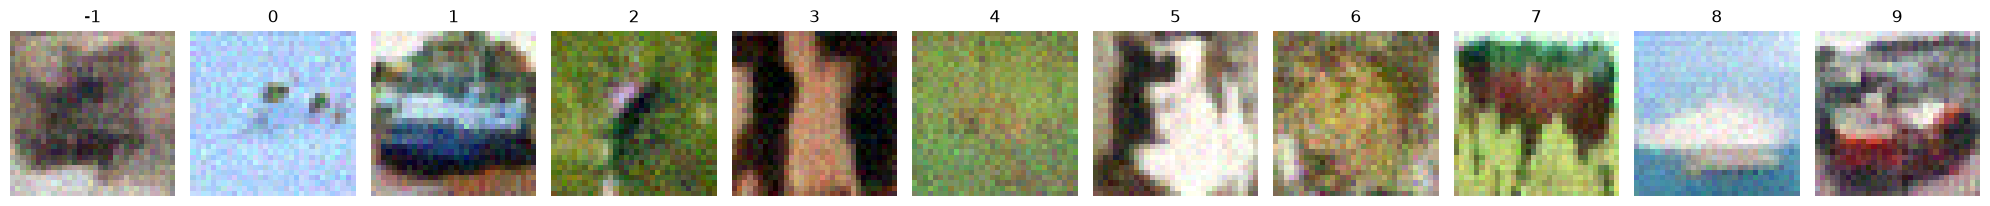

Progressive stage 24/25: changes={'timesteps': (52, 1000)}, resolution=32, sampling t in [52, 1000) range.
Epoch 231/240
390/390 ━━━━━━━━━━━━━━━━━━━━ 31s 31ms/step - noise_loss: 0.0272 - learning_rate: 1.4721e-04
Epoch 232/240
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 0.0270 - learning_rate: 1.3733e-04
Epoch 233/240
390/390 ━━━━━━━━━━━━━━━━━━━━ 16s 41ms/step - noise_loss: 0.0271 - learning_rate: 1.2778e-04
Epoch 234/240
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 49ms/step - noise_loss: 0.0271 - learning_rate: 1.1857e-04
Epoch 235/240
390/390 ━━━━━━━━━━━━━━━━━━━━ 33s 85ms/step - noise_loss: 0.0270 - val_image_loss: 0.0761 - val_loss: 0.0340 - val_noise_loss: 0.0340 - learning_rate: 1.0969e-04
Steps: 50/50


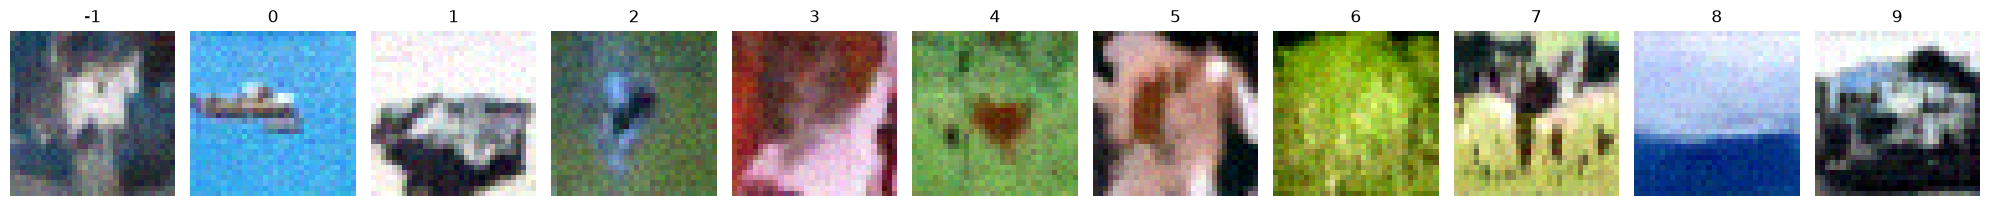

Epoch 236/240
390/390 ━━━━━━━━━━━━━━━━━━━━ 13s 32ms/step - noise_loss: 0.0270 - learning_rate: 1.0115e-04
Epoch 237/240
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 0.0270 - learning_rate: 9.2949e-05
Epoch 238/240
390/390 ━━━━━━━━━━━━━━━━━━━━ 16s 40ms/step - noise_loss: 0.0270 - learning_rate: 8.5089e-05
Epoch 239/240
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 49ms/step - noise_loss: 0.0269 - learning_rate: 7.7570e-05
Epoch 240/240
390/390 ━━━━━━━━━━━━━━━━━━━━ 33s 86ms/step - noise_loss: 0.0270 - val_image_loss: 0.0759 - val_loss: 0.0340 - val_noise_loss: 0.0340 - learning_rate: 7.0394e-05
Steps: 50/50


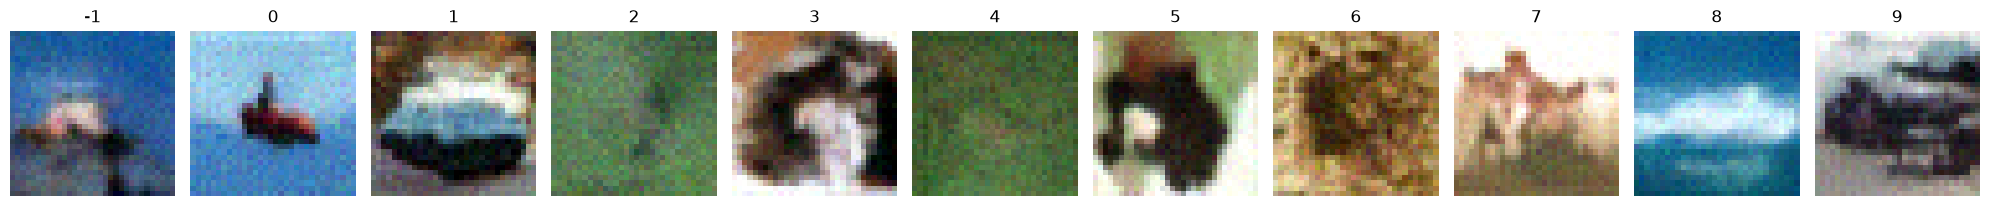

Progressive stage 25/25: changes={'timesteps': (0, 1000)}, resolution=32, sampling t in [0, 1000) range.
Epoch 241/250
390/390 ━━━━━━━━━━━━━━━━━━━━ 29s 27ms/step - noise_loss: 0.0301 - learning_rate: 6.3560e-05
Epoch 242/250
390/390 ━━━━━━━━━━━━━━━━━━━━ 10s 25ms/step - noise_loss: 0.0302 - learning_rate: 5.7072e-05
Epoch 243/250
390/390 ━━━━━━━━━━━━━━━━━━━━ 13s 34ms/step - noise_loss: 0.0302 - learning_rate: 5.0928e-05
Epoch 244/250
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 48ms/step - noise_loss: 0.0301 - learning_rate: 4.5131e-05
Epoch 245/250
390/390 ━━━━━━━━━━━━━━━━━━━━ 33s 85ms/step - noise_loss: 0.0300 - val_image_loss: 0.0740 - val_loss: 0.0327 - val_noise_loss: 0.0327 - learning_rate: 3.9681e-05
Steps: 50/50


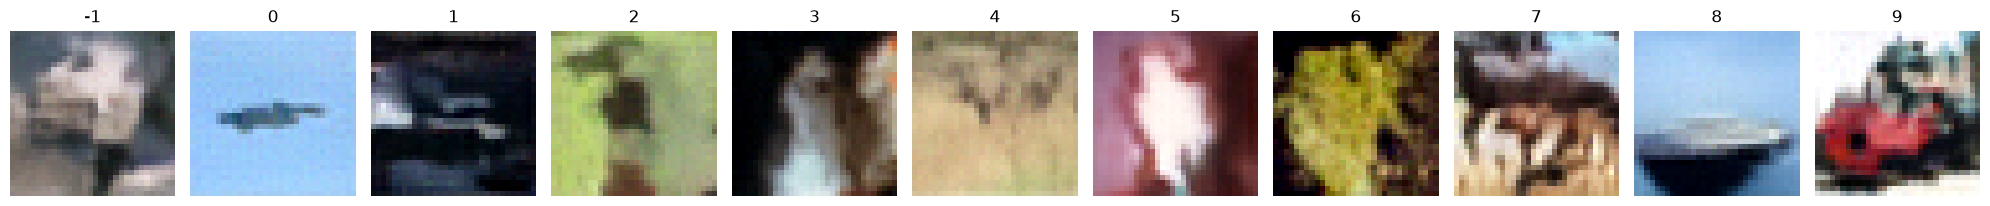

Epoch 246/250
390/390 ━━━━━━━━━━━━━━━━━━━━ 14s 35ms/step - noise_loss: 0.0300 - learning_rate: 3.4579e-05
Epoch 247/250
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 29ms/step - noise_loss: 0.0301 - learning_rate: 2.9825e-05
Epoch 248/250
390/390 ━━━━━━━━━━━━━━━━━━━━ 14s 35ms/step - noise_loss: 0.0301 - learning_rate: 2.5421e-05
Epoch 249/250
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 49ms/step - noise_loss: 0.0301 - learning_rate: 2.1366e-05
Epoch 250/250
390/390 ━━━━━━━━━━━━━━━━━━━━ 21s 54ms/step - noise_loss: 0.0302 - val_image_loss: 0.0777 - val_loss: 0.0324 - val_noise_loss: 0.0324 - learning_rate: 1.7663e-05
Steps: 50/50


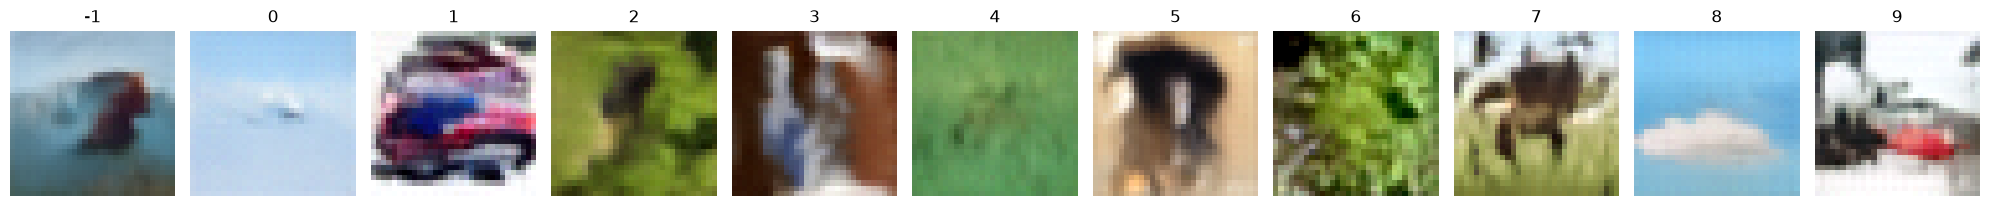

Progressive stage final/full-task: changes={'timesteps': (0, 1000), 'resolution': 32}, resolution=32, sampling t in [0, 1000) range.
Epoch 251/260
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 49ms/step - noise_loss: 0.0303 - learning_rate: 1.4310e-05
Epoch 252/260
390/390 ━━━━━━━━━━━━━━━━━━━━ 17s 43ms/step - noise_loss: 0.0300 - learning_rate: 1.1309e-05
Epoch 253/260
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - noise_loss: 0.0303 - learning_rate: 8.6601e-06
Epoch 254/260
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 29ms/step - noise_loss: 0.0302 - learning_rate: 6.3635e-06
Epoch 255/260
390/390 ━━━━━━━━━━━━━━━━━━━━ 21s 54ms/step - noise_loss: 0.0298 - val_image_loss: 0.0778 - val_loss: 0.0327 - val_noise_loss: 0.0327 - learning_rate: 4.4197e-06
Steps: 50/50


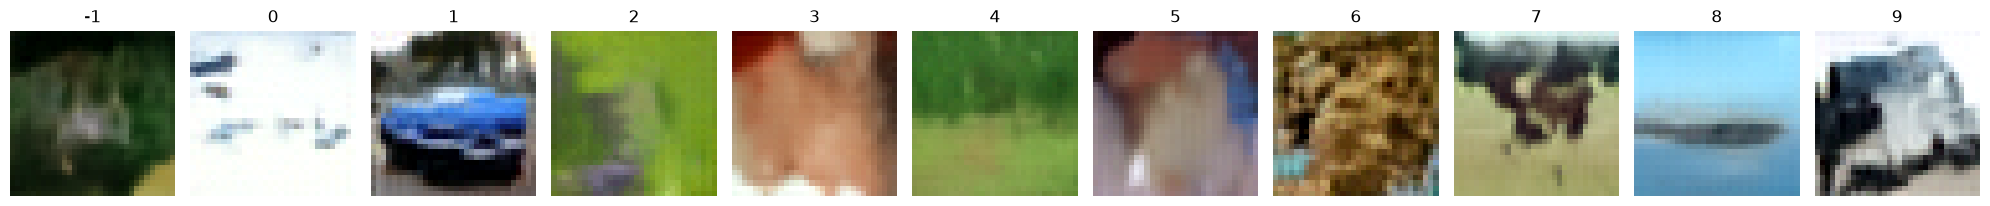

Epoch 256/260
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 49ms/step - noise_loss: 0.0300 - learning_rate: 2.8289e-06
Epoch 257/260
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 49ms/step - noise_loss: 0.0302 - learning_rate: 1.5914e-06
Epoch 258/260
390/390 ━━━━━━━━━━━━━━━━━━━━ 19s 48ms/step - noise_loss: 0.0301 - learning_rate: 7.0738e-07
Epoch 259/260
390/390 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - noise_loss: 0.0298 - learning_rate: 1.7688e-07
Epoch 260/260
390/390 ━━━━━━━━━━━━━━━━━━━━ 12s 31ms/step - noise_loss: 0.0302 - val_image_loss: 0.0767 - val_loss: 0.0324 - val_noise_loss: 0.0324 - learning_rate: 0.0000e+00
Steps: 50/50


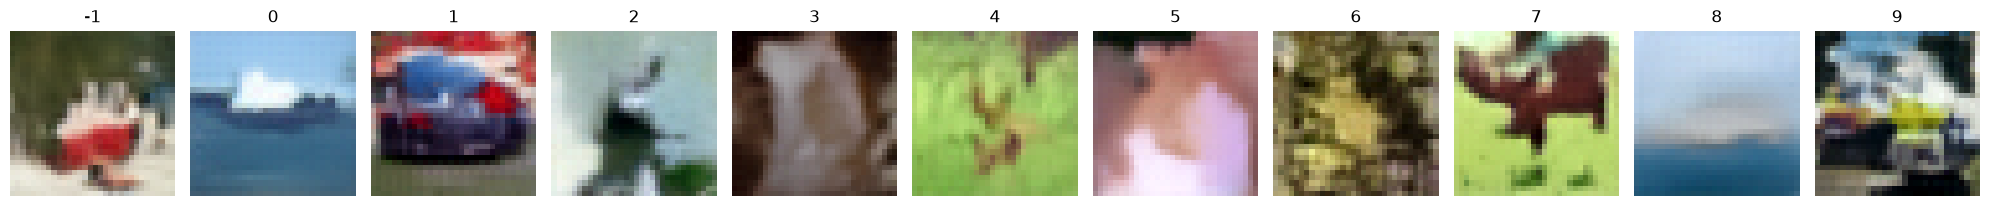

In [8]:
history = model.fit_progressively(
    stage_tasks="timesteps_only", 
    stages_num=stages_num, 
    x=trainset, 
    stage_epochs=epochs, 
    validation_data=valset, 
    callbacks=callbacks_list, 
    validation_freq=val_freq
).history

## Save weights


In [9]:
model.save_weights("./files/models/CIFAR10 DiT/model.weights.h5")

## Evaluate EMA and raw networks


In [10]:
model.evaluate(valset, network_name="ema")

79/79 ━━━━━━━━━━━━━━━━━━━━ 3s 32ms/step - image_loss: 0.0754 - loss: 0.0325 - noise_loss: 0.0325


[<tf.Tensor: shape=(), dtype=float32, numpy=0.032476212829351425>,
 <tf.Tensor: shape=(), dtype=float32, numpy=0.032476212829351425>,
 <tf.Tensor: shape=(), dtype=float32, numpy=0.075388103723526>]

In [11]:
model.evaluate(valset, network_name="raw")

79/79 ━━━━━━━━━━━━━━━━━━━━ 14s 94ms/step - image_loss: 0.0769 - loss: 0.0324 - noise_loss: 0.0324


[<tf.Tensor: shape=(), dtype=float32, numpy=0.03236205130815506>,
 <tf.Tensor: shape=(), dtype=float32, numpy=0.03236205130815506>,
 <tf.Tensor: shape=(), dtype=float32, numpy=0.0768880546092987>]

## Class-conditional samples


Steps: 1000/1000


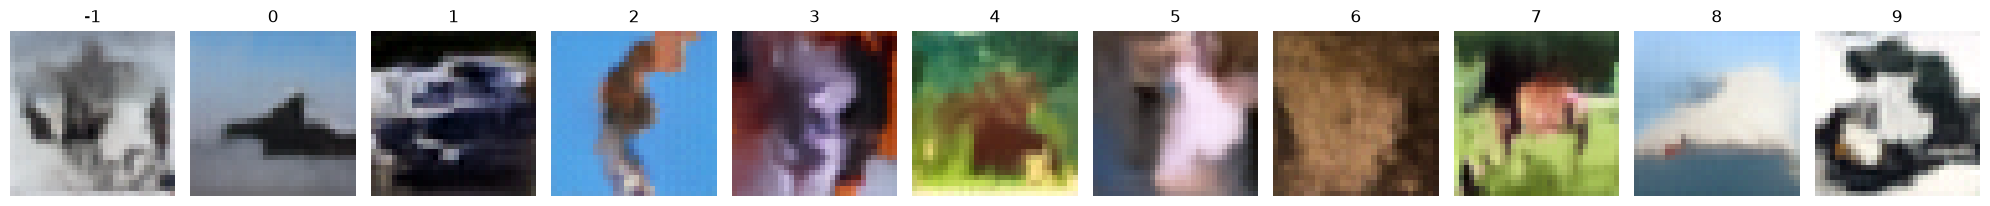

In [12]:
from common.utils import plot_images


imgs = model.sample(
    add_null_label=True, 
    scale=3., 
    eta=1., 
    steps=1_000, 
    verbose=True
)
plot_images(imgs, has_null_label=True)

Steps: 1000/1000


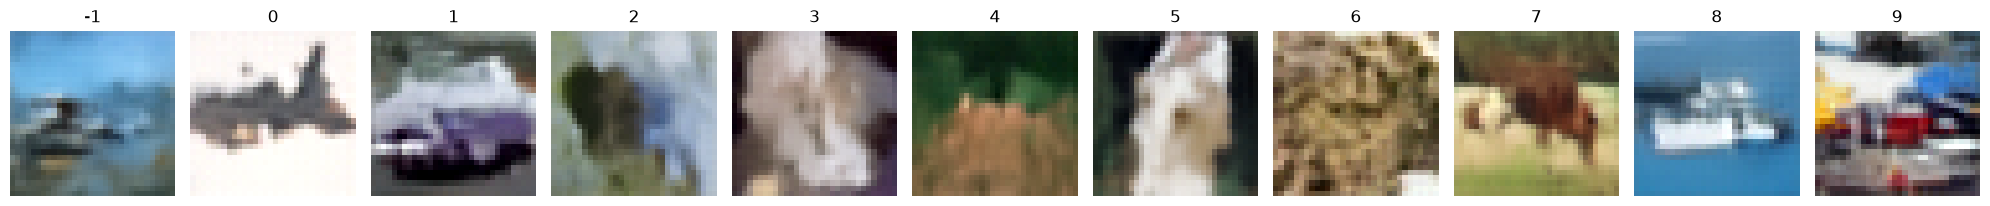

In [13]:
imgs = model.sample(
    add_null_label=True, 
    scale=3., 
    steps=1_000, 
    verbose=True
)
plot_images(imgs, has_null_label=True)

Steps: 50/50


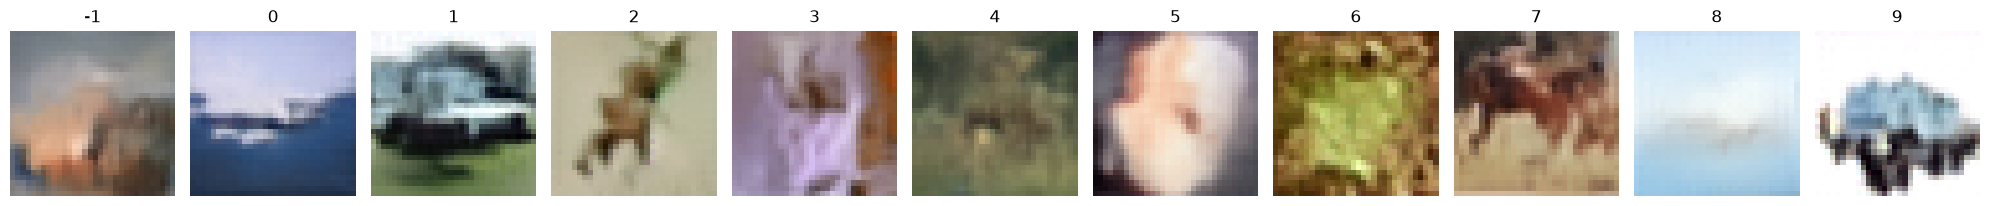

In [14]:
imgs = model.sample(
    add_null_label=True, 
    scale=3., 
    verbose=True
)
plot_images(imgs, has_null_label=True)

Steps: 50/50


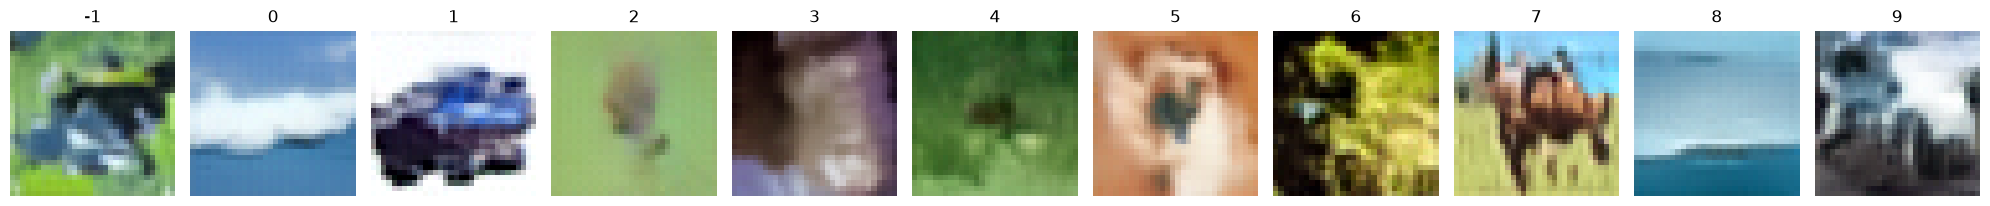

In [15]:
imgs = model.sample(
    add_null_label=True, 
    scale=4., 
    verbose=True
)
plot_images(imgs, has_null_label=True)

## Training history


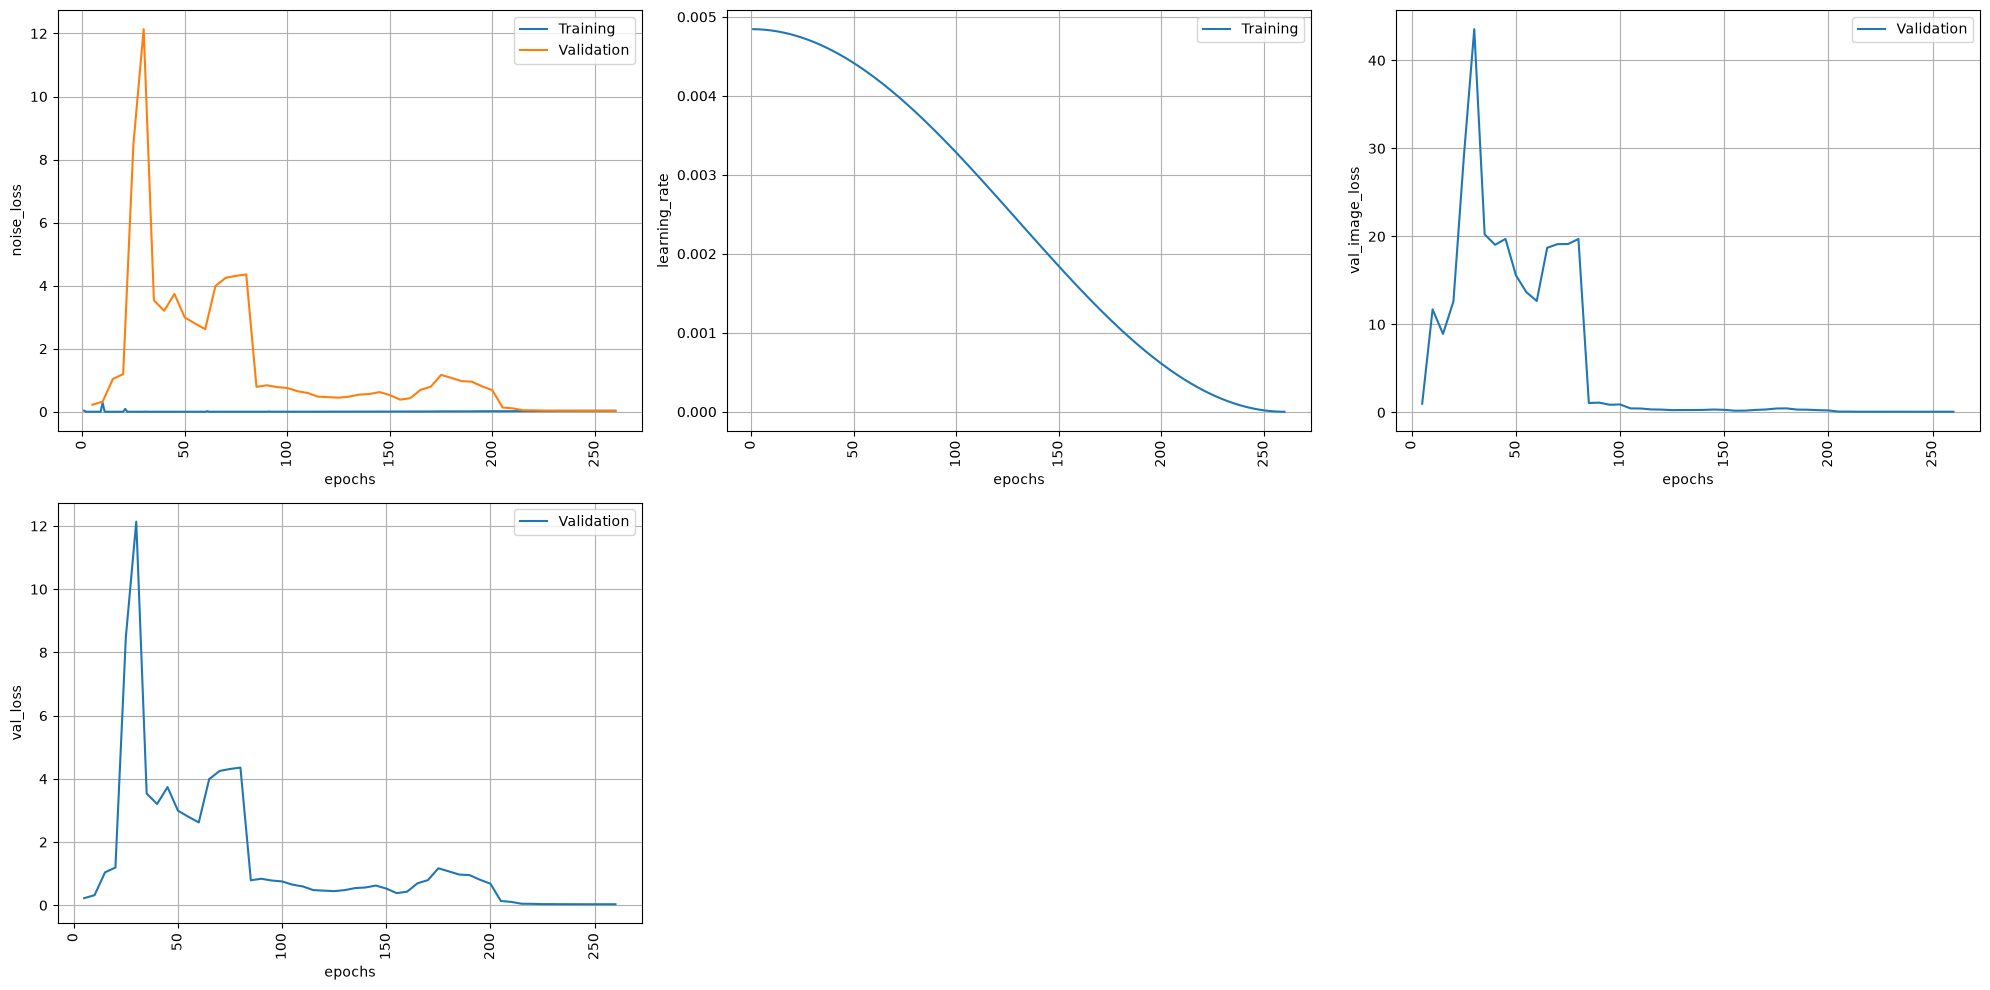

In [16]:
from common.utils import plot_history


plot_history(history, show_all_x_ticks=False)

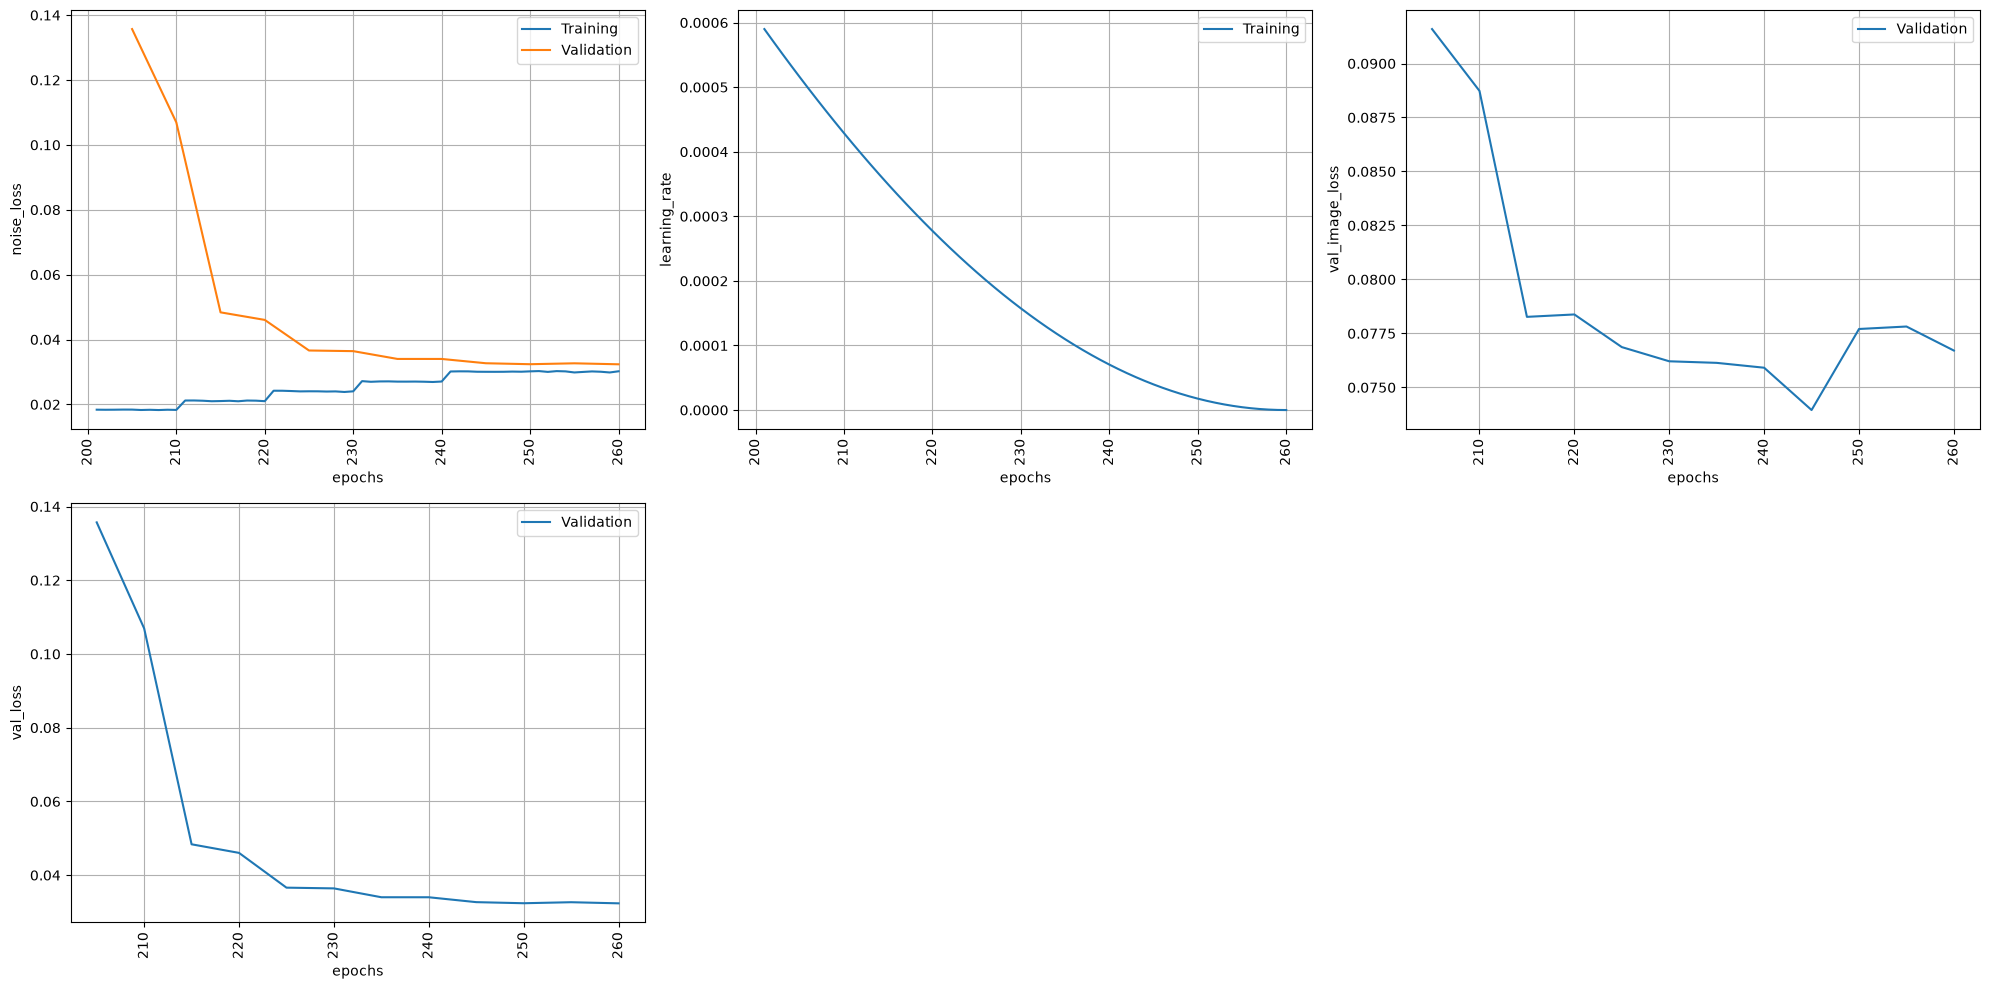

In [17]:
plot_history(history, show_all_x_ticks=False, range_=(200, None))